# Customer Churn and Future Spending Prediction

## Project objective

This notebook uses historical customer purchase behavior to estimate two outcomes:

1. Whether a customer will make no recorded purchase during the next 90 days.
2. How much the customer will spend during that 90-day period, measured in the dataset’s price units.

The goal is to create customer-level predictions that could support retention and customer-prioritization analysis.

## Point-in-time setup

- **Snapshot date:** December 31, 2019
- **Feature data:** Transactions up to and including the snapshot date
- **Outcome period:** January 1 through March 30, 2020
- **Dataset file:** `data/processed/customer_churn_spend_model_2019-12-31.parquet`

Predictor features are calculated from information available by the snapshot date. The outcome period is kept separate to prevent future information from entering the model inputs.

## Prediction targets

| Column | Meaning |
|---|---|
| `churn_90d` | `1` means no recorded purchase in the outcome period; `0` means at least one recorded purchase. |
| `future_spending_90d` | Sum of the customer’s transaction prices during the outcome period. It is `0` when there is no recorded purchase. |

Here, “churn” is shorthand for **no observed purchase during this 90-day period**. It does not establish that a customer permanently left.

## Model inputs

The dataset includes 13 customer behavior features, such as purchase-record counts, distinct purchase days, historical spending, recent activity, and online purchase share.

`customer_id` is kept in the dataset to identify customers, but it is excluded from the predictors. Neither target column is used as a predictor.

## Modeling workflow

1. Validate the saved dataset and separate predictors from targets.
2. Compare models with a simple majority-class baseline.
3. Evaluate classification performance using precision, recall, F1, ROC-AUC, and average precision.
4. Develop a future-spending prediction and assess its error.
5. Examine model explanations and customer-prioritization use cases.
6. Add validation on a later historical cutoff before reporting final performance.

## Interpretation limits

The dataset’s price values are in scaled dataset units, not confirmed currency or profit. A predicted no-purchase outcome is not proof of permanent churn, and historical spending associated with a customer is not confirmed lost revenue.

In [2]:
from pathlib import Path

import duckdb
import pandas as pd
from IPython.display import display

# Find the project folder from the notebook's current working directory.
project_root = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find the project's data/processed folder."
    )

dataset_path = (
    project_root
    / "data"
    / "processed"
    / "customer_churn_model_2019-12-31.parquet"
)

if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset file not found: {dataset_path}")

con = duckdb.connect()
sql_path = str(dataset_path).replace("'", "''")

con.execute(f"""
CREATE VIEW churn_model_data AS
SELECT *
FROM read_parquet('{sql_path}')
""")

file_check = con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    SUM(CASE WHEN churn_90d = 0 THEN 1 ELSE 0 END) AS returned_customers,
    SUM(CASE WHEN churn_90d = 1 THEN 1 ELSE 0 END) AS no_purchase_customers
FROM churn_model_data
""").df()

print(f"Dataset file: {dataset_path}")
display(file_check)

Dataset file: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_churn_model_2019-12-31.parquet


,rows,unique_customers,returned_customers,no_purchase_customers
0,1116877,1116877,389053.0,727824.0


In [3]:
transactions_path = project_root / "data" / "processed" / "transactions.parquet"

if not transactions_path.is_file():
    raise FileNotFoundError(f"Transactions file not found: {transactions_path}")

transactions_sql_path = str(transactions_path).replace("'", "''")

con.execute(f"""
CREATE OR REPLACE VIEW transactions AS
SELECT *
FROM read_parquet('{transactions_sql_path}')
""")

cutoff_date = "2019-12-31"

con.execute(f"""
CREATE OR REPLACE TEMP TABLE churn_spend_model_data AS
WITH future_spending AS (
    SELECT
        customer_id,
        SUM(price) AS future_spending_90d
    FROM transactions
    WHERE t_dat > DATE '{cutoff_date}'
      AND t_dat <= DATE '{cutoff_date}' + INTERVAL 90 DAY
    GROUP BY customer_id
)
SELECT
    d.*,
    COALESCE(f.future_spending_90d, 0.0) AS future_spending_90d
FROM churn_model_data d
LEFT JOIN future_spending f
    ON d.customer_id = f.customer_id
""")

target_check = con.execute("""
SELECT
    COUNT(*) AS customers,
    SUM(CASE
        WHEN churn_90d = 1 AND future_spending_90d > 0 THEN 1
        ELSE 0
    END) AS no_purchase_label_but_positive_spending,
    SUM(CASE
        WHEN churn_90d = 0 AND future_spending_90d <= 0 THEN 1
        ELSE 0
    END) AS returned_label_but_zero_spending,
    ROUND(AVG(future_spending_90d), 4) AS average_future_spending,
    ROUND(SUM(future_spending_90d), 2) AS total_future_spending
FROM churn_spend_model_data
""").df()

display(target_check)

,customers,no_purchase_label_but_positive_spending,returned_label_but_zero_spending,average_future_spending,total_future_spending
0,1116877,0.0,0.0,0.0696,77767.04


In [4]:
model_file = (
    project_root
    / "data"
    / "processed"
    / "customer_churn_spend_model_2019-12-31.parquet"
)

model_file.parent.mkdir(parents=True, exist_ok=True)
model_sql_path = str(model_file).replace("'", "''")

con.execute(f"""
COPY (
    SELECT *
    FROM churn_spend_model_data
)
TO '{model_sql_path}'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")

saved_rows = con.execute(
    f"SELECT COUNT(*) FROM read_parquet('{model_sql_path}')"
).fetchone()[0]

print(f"Saved modeling dataset: {model_file}")
print(f"Rows verified: {saved_rows:,}")
print(f"File size: {model_file.stat().st_size / (1024 ** 2):,.2f} MiB")

Saved modeling dataset: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_churn_spend_model_2019-12-31.parquet
Rows verified: 1,116,877
File size: 54.43 MiB


In [5]:
import numpy as np

feature_columns = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

feature_select_sql = ",\n    ".join(feature_columns)

model_data = con.execute(f"""
SELECT
    {feature_select_sql},
    churn_90d,
    future_spending_90d
FROM read_parquet('{model_sql_path}')
""").df()

# Keep predictors and outcomes separate.
X = model_data[feature_columns].apply(pd.to_numeric, errors="raise")
y_churn = model_data["churn_90d"].astype("int8")
y_future_spending = model_data["future_spending_90d"].astype("float32")

print(f"Rows: {len(model_data):,}")
print(f"Predictor columns: {X.shape[1]}")
print(f"Missing predictor values: {int(X.isna().sum().sum()):,}")
print(
    "Non-finite predictor values:",
    int((~np.isfinite(X.to_numpy(dtype="float64"))).sum())
)
print(f"Customers with a future purchase: {(y_churn == 0).sum():,}")
print(f"Customers with no future purchase: {(y_churn == 1).sum():,}")
print(f"Customers with positive future spending: {(y_future_spending > 0).sum():,}")

Rows: 1,116,877
Predictor columns: 13
Missing predictor values: 0
Non-finite predictor values: 0
Customers with a future purchase: 389,053
Customers with no future purchase: 727,824
Customers with positive future spending: 389,053


In [6]:
!pip install scikit-learn

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Keep the outcome proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_churn,
    test_size=0.20,
    random_state=42,
    stratify=y_churn
)

# Benchmark: always predict no purchase within 90 days.
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

baseline_results = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, baseline_predictions),
    "precision_no_purchase": precision_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, baseline_probabilities),
    "pr_auc_average_precision": average_precision_score(
        y_test, baseline_probabilities
    ),
}])

display(baseline_results.round(4))

,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,pr_auc_average_precision
0,0.6517,0.6517,1.0,0.7891,0.5,0.6517


## Logistic regression

,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,pr_auc_average_precision
0,Always predict no purchase,0.6517,0.6517,1.0000,0.7891,0.5000,0.6517
1,Logistic regression,0.7727,0.7956,0.8764,0.8340,0.8245,0.8817


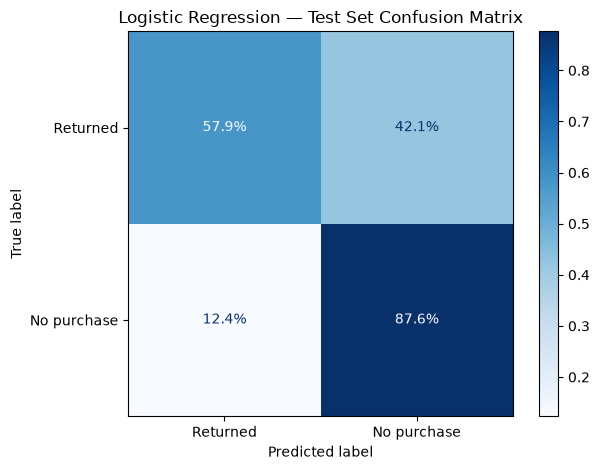

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Compress long-tailed count and spending features.
log_features = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
]

X_train_log = X_train.copy()
X_test_log = X_test.copy()

for column in log_features:
    X_train_log[column] = np.log1p(X_train_log[column])
    X_test_log[column] = np.log1p(X_test_log[column])

# Train logistic regression on the training set only.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=300, random_state=42)
)

logistic_model.fit(X_train_log, y_train)

logistic_predictions = logistic_model.predict(X_test_log)
logistic_probabilities = logistic_model.predict_proba(X_test_log)[:, 1]

def get_metrics(name, actual, predicted, probability):
    return {
        "model": name,
        "accuracy": accuracy_score(actual, predicted),
        "precision_no_purchase": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall_no_purchase": recall_score(
            actual, predicted, zero_division=0
        ),
        "f1_no_purchase": f1_score(
            actual, predicted, zero_division=0
        ),
        "roc_auc": roc_auc_score(actual, probability),
        "pr_auc_average_precision": average_precision_score(
            actual, probability
        ),
    }

model_comparison = pd.DataFrame([
    get_metrics(
        "Always predict no purchase",
        y_test,
        baseline_predictions,
        baseline_probabilities
    ),
    get_metrics(
        "Logistic regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),
])

display(model_comparison.round(4))

# Show correct and incorrect classifications as percentages within each true class.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Returned", "No purchase"],
    normalize="true",
    values_format=".1%",
    cmap="Blues"
)

plt.title("Logistic Regression — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## Histogram-based Gradient Boosting

,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,pr_auc_average_precision
0,Always predict no purchase,0.6517,0.6517,1.0000,0.7891,0.5000,0.6517
1,Logistic regression,0.7727,0.7956,0.8764,0.8340,0.8245,0.8817
2,Histogram Gradient Boosting,0.7731,0.7972,0.8743,0.8340,0.8260,0.8853


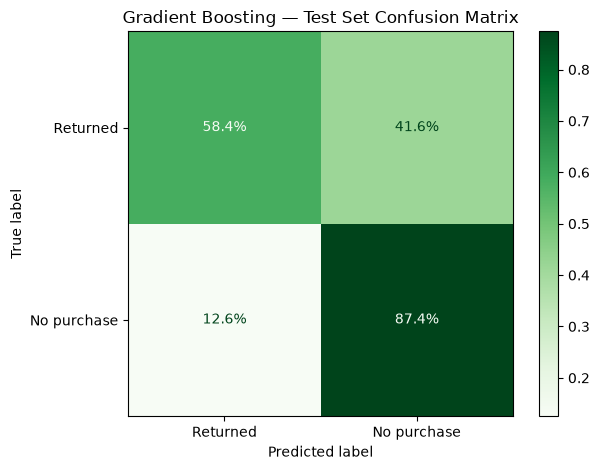

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay

gradient_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=42
)

# Use the original, unscaled features for the tree-based model.
gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)
gradient_probabilities = gradient_model.predict_proba(X_test)[:, 1]

gradient_results = pd.DataFrame([
    get_metrics(
        "Histogram Gradient Boosting",
        y_test,
        gradient_predictions,
        gradient_probabilities
    )
])

model_comparison = pd.concat(
    [model_comparison, gradient_results],
    ignore_index=True
)

display(model_comparison.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gradient_predictions,
    display_labels=["Returned", "No purchase"],
    normalize="true",
    values_format=".1%",
    cmap="Greens"
)

plt.title("Gradient Boosting — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## Compare thresholds

In [10]:
!pip install jinja2

,threshold,customers_flagged,share_flagged_pct,precision,recall,f1_score
0,0.30,192229,86.1%,0.730,0.964,0.831
1,0.40,176876,79.2%,0.764,0.928,0.838
2,0.50,159657,71.5%,0.797,0.874,0.834
3,0.60,140609,62.9%,0.831,0.802,0.816
4,0.70,119572,53.5%,0.862,0.708,0.777


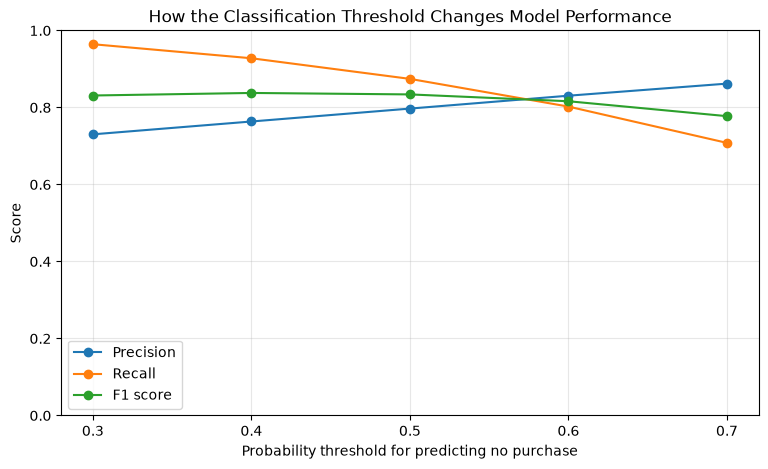

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# Class 1 means no purchase during the following 90 days.
no_purchase_probability = gradient_model.predict_proba(X_test)[:, 1]

threshold_rows = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predicted_no_purchase = (
        no_purchase_probability >= threshold
    ).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "customers_flagged": int(predicted_no_purchase.sum()),
        "share_flagged_pct": 100 * predicted_no_purchase.mean(),
        "precision": precision_score(
            y_test, predicted_no_purchase, zero_division=0
        ),
        "recall": recall_score(
            y_test, predicted_no_purchase, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predicted_no_purchase, zero_division=0
        ),
    })

threshold_results = pd.DataFrame(threshold_rows)

display(
    threshold_results.style.format({
        "threshold": "{:.2f}",
        "share_flagged_pct": "{:.1f}%",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
    })
)

# Plot how precision and recall change as the threshold changes.
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["f1_score"],
    marker="o",
    label="F1 score"
)

plt.xlabel("Probability threshold for predicting no purchase")
plt.ylabel("Score")
plt.title("How the Classification Threshold Changes Model Performance")
plt.xticks(threshold_results["threshold"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Among the tested thresholds, 0.40 produced the highest F1 score (0.837), with 92.7% recall. It flags 79.1% of test customers, so a business with limited campaign capacity may need to prioritize customers by predicted risk. The appropriate cutoff depends on campaign capacity and the cost of missed customers versus unnecessary contacts.

,top_customer_share_pct,customers_targeted,no_purchase_customers_found,precision_pct,recall_pct,lift_vs_average
0,10%,22337,21165,94.8%,14.5%,1.45x
1,20%,44675,41666,93.3%,28.6%,1.43x
2,30%,67012,61427,91.7%,42.2%,1.41x
3,40%,89350,80103,89.7%,55.0%,1.38x


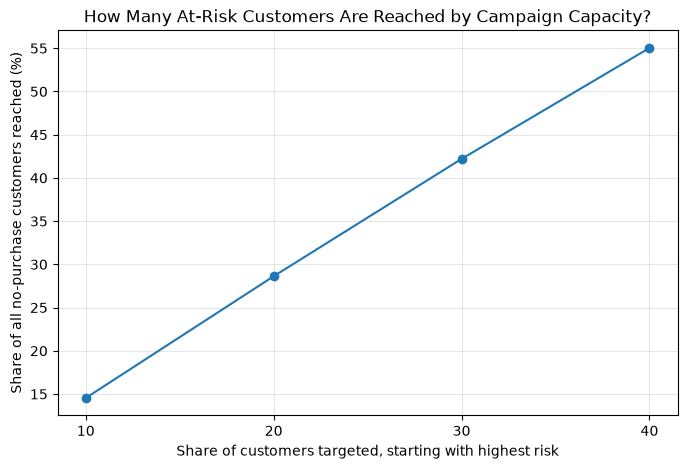

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual_no_purchase = np.asarray(y_test).astype(int)
risk_scores = np.asarray(no_purchase_probability)

# Sort customers from highest predicted no-purchase risk to lowest.
ranked_indices = np.argsort(risk_scores)[::-1]

baseline_no_purchase_rate = actual_no_purchase.mean()
top_group_rows = []

for share in [0.10, 0.20, 0.30, 0.40]:
    number_to_target = int(len(ranked_indices) * share)
    selected_indices = ranked_indices[:number_to_target]

    no_purchase_found = actual_no_purchase[selected_indices].sum()
    precision_at_group = no_purchase_found / number_to_target
    recall_at_group = no_purchase_found / actual_no_purchase.sum()
    lift = precision_at_group / baseline_no_purchase_rate

    top_group_rows.append({
        "top_customer_share_pct": share * 100,
        "customers_targeted": number_to_target,
        "no_purchase_customers_found": int(no_purchase_found),
        "precision_pct": precision_at_group * 100,
        "recall_pct": recall_at_group * 100,
        "lift_vs_average": lift,
    })

top_group_results = pd.DataFrame(top_group_rows)

display(
    top_group_results.style.format({
        "top_customer_share_pct": "{:.0f}%",
        "precision_pct": "{:.1f}%",
        "recall_pct": "{:.1f}%",
        "lift_vs_average": "{:.2f}x",
    })
)

plt.figure(figsize=(8, 5))
plt.plot(
    top_group_results["top_customer_share_pct"],
    top_group_results["recall_pct"],
    marker="o"
)
plt.xlabel("Share of customers targeted, starting with highest risk")
plt.ylabel("Share of all no-purchase customers reached (%)")
plt.title("How Many At-Risk Customers Are Reached by Campaign Capacity?")
plt.xticks([10, 20, 30, 40])
plt.grid(alpha=0.3)
plt.show()

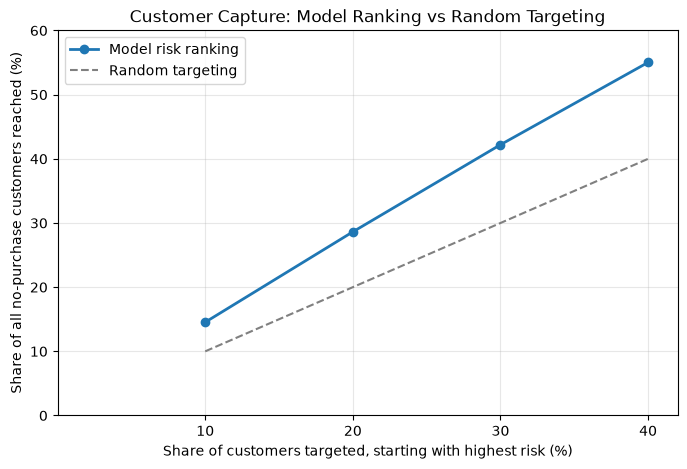

In [13]:
x = top_group_results["top_customer_share_pct"]
y = top_group_results["recall_pct"]

plt.figure(figsize=(8, 5))
plt.plot(x, y, marker="o", linewidth=2, label="Model risk ranking")
plt.plot(x, x, linestyle="--", color="gray", label="Random targeting")

plt.xlabel("Share of customers targeted, starting with highest risk (%)")
plt.ylabel("Share of all no-purchase customers reached (%)")
plt.title("Customer Capture: Model Ranking vs Random Targeting")
plt.xticks([10, 20, 30, 40])
plt.xlim(0, 42)
plt.ylim(0, 60)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The model’s customer ranking outperformed random targeting across the tested campaign sizes. Targeting the highest-risk 20% reached approximately 29% of all customers with no purchase in the next 90 days, compared with 20% under random targeting. This supports using the model to prioritize customers, while campaign effectiveness would need to be tested separately.

## Model Interpretation: Permutation Importance
Permutation importance estimates how much each feature contributes to the model’s predictive performance. We shuffle one feature at a time and measure the resulting change in average precision. A larger decrease suggests the model relied more on that feature. This shows predictive importance, not cause and effect.

,feature,importance_mean,importance_std
10,purchase_days_last_365d,0.01745,0.00147
6,active_months,0.01375,0.00130
9,purchase_days_last_180d,0.00518,0.00052
1,purchase_days,0.00410,0.00058
5,customer_history_days,0.00341,0.00135
12,online_record_share,0.00286,0.00084
2,distinct_articles,0.00200,0.00013
8,purchase_days_last_90d,0.00112,0.00041
3,historical_spending,0.00092,0.00043
11,online_records,0.00054,0.00025


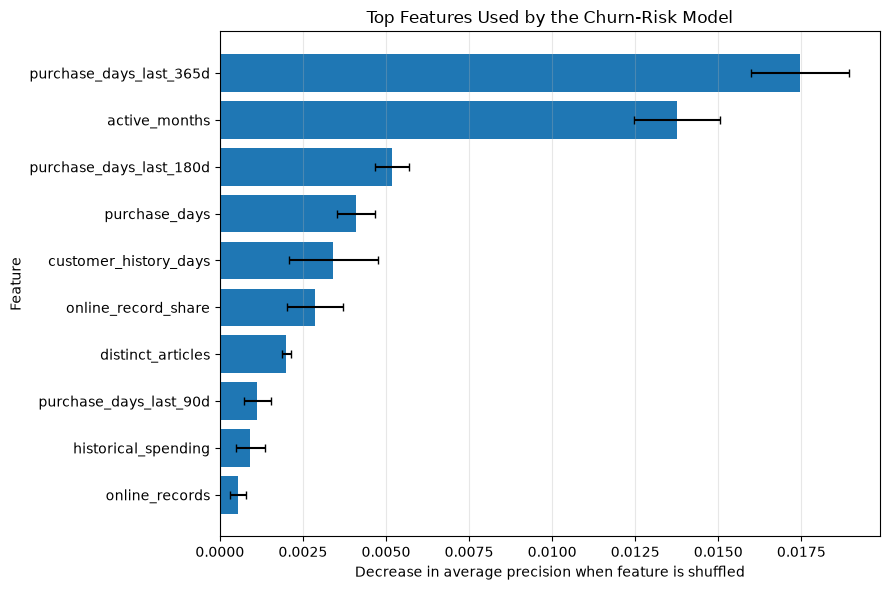

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Take a reproducible sample from the test set.
sample_size = min(10_000, len(X_test))
sample_indices = np.random.default_rng(42).choice(
    len(X_test),
    size=sample_size,
    replace=False
)

X_importance_sample = X_test.iloc[sample_indices]
y_importance_sample = np.asarray(y_test)[sample_indices]

# Shuffle one feature at a time and measure the drop in average precision.
importance_result = permutation_importance(
    estimator=gradient_model,
    X=X_importance_sample,
    y=y_importance_sample,
    scoring="average_precision",
    n_repeats=3,
    random_state=42
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std,
}).sort_values("importance_mean", ascending=False)

display(
    feature_importance.head(10).style.format({
        "importance_mean": "{:.5f}",
        "importance_std": "{:.5f}",
    })
)

# Plot the ten most important features.
plot_data = feature_importance.head(10).sort_values("importance_mean")

plt.figure(figsize=(9, 6))
plt.barh(
    plot_data["feature"],
    plot_data["importance_mean"],
    xerr=plot_data["importance_std"],
    capsize=3
)
plt.xlabel("Decrease in average precision when feature is shuffled")
plt.ylabel("Feature")
plt.title("Top Features Used by the Churn-Risk Model")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The permutation importance analysis showed that purchase days in the previous 365 days and the number of active months were the most useful features for ranking no-purchase risk. This suggests that sustained purchase activity carries useful predictive information. These are model associations, not causal effects, and importance can be shared across related features.

## Temporal Validation Dataset
To test the model on a later period, customer features are calculated using transactions through March 31, 2020. The target records whether the customer made any purchase during the following 90 days. This evaluates the model on a future time window rather than a random sample from the original cutoff.

In [15]:

import pandas as pd

validation_cutoff = "2020-03-31"

con.execute(f"""
CREATE OR REPLACE TEMP TABLE temporal_validation_dataset AS
WITH historical_transactions AS (
    SELECT *
    FROM transactions
    WHERE t_dat <= DATE '{validation_cutoff}'
),

future_activity AS (
    SELECT
        customer_id,
        COUNT(*) AS future_transaction_records
    FROM transactions
    WHERE t_dat > DATE '{validation_cutoff}'
      AND t_dat <= DATE '{validation_cutoff}' + INTERVAL 90 DAY
    GROUP BY customer_id
),

behavior_features AS (
    SELECT
        customer_id,

        COUNT(*) AS transaction_records,
        COUNT(DISTINCT t_dat) AS purchase_days,
        COUNT(DISTINCT article_id) AS distinct_articles,
        SUM(price) AS historical_spending,
        AVG(price) AS average_record_price,

        DATEDIFF(
            'day',
            MIN(t_dat),
            DATE '{validation_cutoff}'
        ) + 1 AS customer_history_days,

        COUNT(DISTINCT DATE_TRUNC('month', t_dat)) AS active_months,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{validation_cutoff}' - INTERVAL 30 DAY
            THEN t_dat
        END) AS purchase_days_last_30d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{validation_cutoff}' - INTERVAL 90 DAY
            THEN t_dat
        END) AS purchase_days_last_90d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{validation_cutoff}' - INTERVAL 180 DAY
            THEN t_dat
        END) AS purchase_days_last_180d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{validation_cutoff}' - INTERVAL 365 DAY
            THEN t_dat
        END) AS purchase_days_last_365d,

        SUM(CASE
            WHEN sales_channel_id = 2 THEN 1
            ELSE 0
        END) AS online_records,

        1.0 * SUM(CASE
            WHEN sales_channel_id = 2 THEN 1
            ELSE 0
        END) / COUNT(*) AS online_record_share

    FROM historical_transactions
    GROUP BY customer_id
)

SELECT
    b.*,
    CASE
        WHEN COALESCE(f.future_transaction_records, 0) = 0 THEN 1
        ELSE 0
    END AS churn_90d
FROM behavior_features b
LEFT JOIN future_activity f
    ON b.customer_id = f.customer_id
""")

# Check the number of customers and the new target balance.
temporal_validation_check = con.execute("""
SELECT
    COUNT(*) AS customer_rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    SUM(CASE WHEN churn_90d = 0 THEN 1 ELSE 0 END) AS returned_customers,
    SUM(CASE WHEN churn_90d = 1 THEN 1 ELSE 0 END) AS no_purchase_customers
FROM temporal_validation_dataset
""").df()

display(temporal_validation_check)

# Check that the validation table has the expected columns.
display(
    con.execute("DESCRIBE temporal_validation_dataset").df()
)

,customer_rows,unique_customers,returned_customers,no_purchase_customers
0,1195314,1195314,432500.0,762814.0


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,transaction_records,BIGINT,YES,None,None,None
2,purchase_days,BIGINT,YES,None,None,None
3,distinct_articles,BIGINT,YES,None,None,None
4,historical_spending,DOUBLE,YES,None,None,None
5,average_record_price,DOUBLE,YES,None,None,None
6,customer_history_days,BIGINT,YES,None,None,None
7,active_months,BIGINT,YES,None,None,None
8,purchase_days_last_30d,BIGINT,YES,None,None,None
9,purchase_days_last_90d,BIGINT,YES,None,None,None


## Temporal Model Evaluation
The trained model is evaluated on customers’ behavior through March 31, 2020, with the target measured over the next 90 days. The model is not retrained on this later period. This tests whether its performance carries forward in time.

,customers,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision
0,"1,195,314",0.7622,0.7729,0.8886,0.8267,0.8174,0.8730


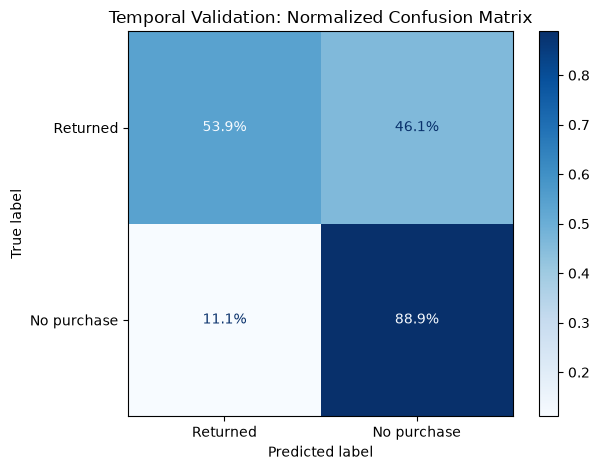

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
)

import matplotlib.pyplot as plt
import pandas as pd

# Use the same 13 predictors and their order from model training.
model_feature_columns = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

validation_df = con.execute("""
    SELECT *
    FROM temporal_validation_dataset
""").df()

# Confirm that all model predictors are present.
missing_features = set(model_feature_columns) - set(validation_df.columns)

if missing_features:
    raise ValueError(f"Missing model features: {missing_features}")

X_temporal = validation_df[model_feature_columns].astype("float64")
y_temporal = validation_df["churn_90d"].astype(int)

# Score each customer with the model trained on the earlier cutoff.
temporal_probability = gradient_model.predict_proba(X_temporal)[:, 1]

# Keep the same 0.50 threshold used for the original model comparison.
temporal_prediction = (temporal_probability >= 0.50).astype(int)

temporal_metrics = pd.DataFrame([{
    "customers": len(y_temporal),
    "accuracy": accuracy_score(y_temporal, temporal_prediction),
    "precision_no_purchase": precision_score(
        y_temporal, temporal_prediction, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_temporal, temporal_prediction, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_temporal, temporal_prediction, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_temporal, temporal_probability),
    "average_precision": average_precision_score(
        y_temporal, temporal_probability
    ),
}])

display(
    temporal_metrics.style.format({
        "customers": "{:,}",
        "accuracy": "{:.4f}",
        "precision_no_purchase": "{:.4f}",
        "recall_no_purchase": "{:.4f}",
        "f1_no_purchase": "{:.4f}",
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
    })
)

ConfusionMatrixDisplay.from_predictions(
    y_temporal,
    temporal_prediction,
    labels=[0, 1],
    display_labels=["Returned", "No purchase"],
    normalize="true",
    values_format=".1%",
    cmap="Blues",
)

plt.title("Temporal Validation: Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

Temporal validation showed a modest performance decline compared with the random test split. On the later period, the model achieved 0.8173 ROC-AUC, 0.8727 average precision, and 88.9% recall for the no-purchase class. It continued to identify most no-purchase customers, while also flagging some customers who later returned. These results support using the model to prioritize customers for further evaluation; they do not establish that a campaign would change purchase behavior.

## Revenue Prediction: Understand the Target
The target, future_spending_90d, is each customer’s recorded spending during the 90 days after the cutoff. It is zero for customers with no purchase. We first inspect the zero-spend share and the distribution among customers who did spend before choosing a regression approach.

,customers,zero_spend_customers,positive_spend_customers,average_spend_all_customers,total_future_spending,average_spend_positive_customers,median_spend_positive_customers,p95_spend_positive_customers,maximum_future_spending
0,1116877,727824.0,389053.0,0.0696,77767.0363,0.1999,0.1153,0.6585,10.5247


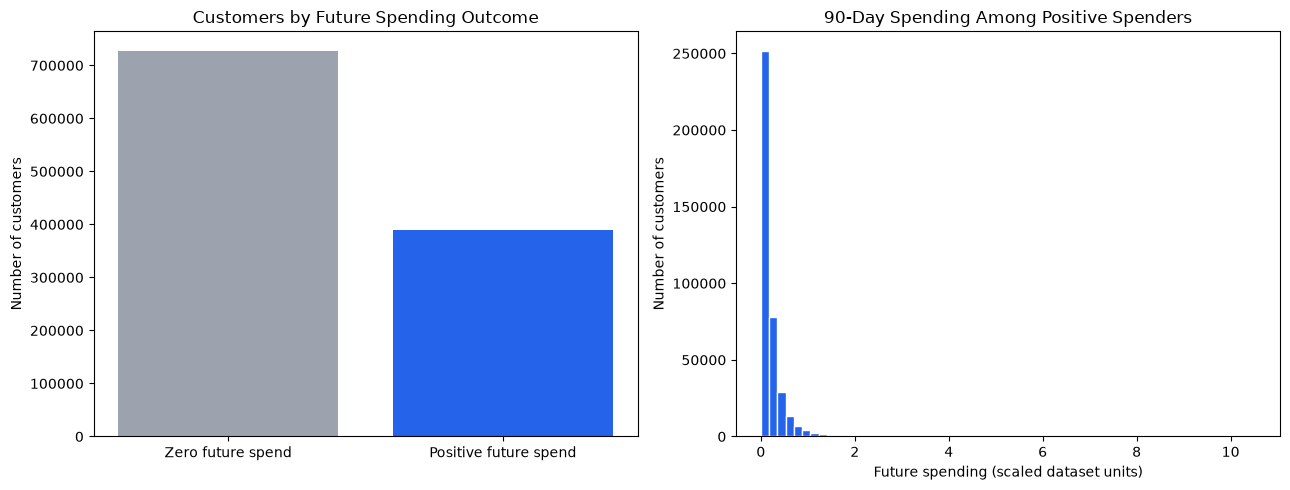

In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

model_dataset_path = (
    Path(project_root)
    / "data"
    / "processed"
    / "customer_churn_spend_model_2019-12-31.parquet"
)

if not model_dataset_path.is_file():
    raise FileNotFoundError(
        f"Modeling dataset not found: {model_dataset_path}"
    )

# Create a DuckDB view of the saved modeling dataset.
dataset_path_sql = str(model_dataset_path).replace("\\", "/").replace("'", "''")

con.execute(f"""
CREATE OR REPLACE TEMP VIEW spend_model_data AS
SELECT *
FROM read_parquet('{dataset_path_sql}')
""")

# Summarize future spending for all customers and for positive spenders.
spending_summary = con.execute("""
SELECT
    COUNT(*) AS customers,
    SUM(CASE WHEN future_spending_90d = 0 THEN 1 ELSE 0 END)
        AS zero_spend_customers,
    SUM(CASE WHEN future_spending_90d > 0 THEN 1 ELSE 0 END)
        AS positive_spend_customers,
    AVG(future_spending_90d) AS average_spend_all_customers,
    SUM(future_spending_90d) AS total_future_spending,
    AVG(CASE WHEN future_spending_90d > 0
        THEN future_spending_90d END) AS average_spend_positive_customers,
    MEDIAN(CASE WHEN future_spending_90d > 0
        THEN future_spending_90d END) AS median_spend_positive_customers,
    QUANTILE_CONT(
        CASE WHEN future_spending_90d > 0
             THEN future_spending_90d END,
        0.95
    ) AS p95_spend_positive_customers,
    MAX(future_spending_90d) AS maximum_future_spending
FROM spend_model_data
""").df()

display(spending_summary.round(4))

# Load only the positive target values for the distribution plot.
positive_spending = con.execute("""
SELECT future_spending_90d
FROM spend_model_data
WHERE future_spending_90d > 0
""").df()["future_spending_90d"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Show how many customers had zero versus positive future spending.
axes[0].bar(
    ["Zero future spend", "Positive future spend"],
    [
        int(spending_summary.loc[0, "zero_spend_customers"]),
        int(spending_summary.loc[0, "positive_spend_customers"]),
    ],
    color=["#9CA3AF", "#2563EB"]
)
axes[0].set_title("Customers by Future Spending Outcome")
axes[0].set_ylabel("Number of customers")
axes[0].ticklabel_format(axis="y", style="plain")

# Show the amount distribution only among customers who spent.
axes[1].hist(
    positive_spending,
    bins=60,
    color="#2563EB",
    edgecolor="white"
)
axes[1].set_title("90-Day Spending Among Positive Spenders")
axes[1].set_xlabel("Future spending (scaled dataset units)")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

## Conditional 90-Day Spending Model
Spending is zero for customers who make no purchase and strongly right-skewed among customers who do. This model estimates future spending only for customers with positive future spending. The target is transformed with log1p during training to reduce the influence of unusually large amounts. This is only the spending component; it does not yet estimate each customer’s overall expected spend.

,model,MAE,RMSE,R2
0,Median baseline,0.1422,0.2773,-0.1014
1,Histogram Gradient Boosting,0.1245,0.2169,0.3259


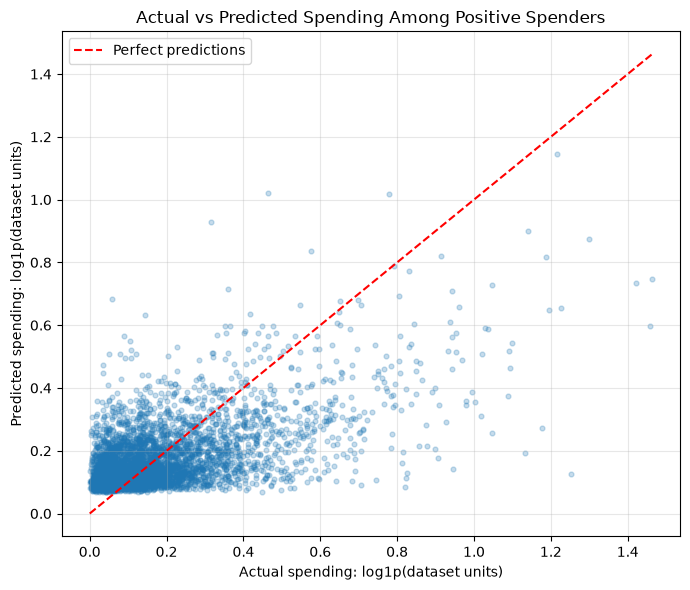

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

model_feature_columns = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

# Load the predictors and future spending target.
spending_model_data = con.execute(f"""
    SELECT
        {", ".join(model_feature_columns)},
        future_spending_90d
    FROM spend_model_data
""").df()

X_spending = spending_model_data[model_feature_columns].astype("float64")
spending_target = spending_model_data["future_spending_90d"].to_numpy()

# Split customers once, stratifying by whether they had positive future spending.
customer_indices = np.arange(len(spending_model_data))
spender_label = (spending_target > 0).astype(int)

train_indices, test_indices = train_test_split(
    customer_indices,
    test_size=0.20,
    random_state=42,
    stratify=spender_label
)

# Fit and evaluate only among positive spenders.
positive_train_indices = train_indices[spending_target[train_indices] > 0]
positive_test_indices = test_indices[spending_target[test_indices] > 0]

X_train_spenders = X_spending.iloc[positive_train_indices]
X_test_spenders = X_spending.iloc[positive_test_indices]

y_train_spenders = spending_target[positive_train_indices]
y_test_spenders = spending_target[positive_test_indices]

# Train on log1p spending to reduce the effect of the long right tail.
y_train_log = np.log1p(y_train_spenders)

# Simple baseline: predict the training-set median spending amount.
spending_baseline = DummyRegressor(strategy="median")
spending_baseline.fit(
    X_train_spenders,
    y_train_log
)

# Gradient boosting model for positive spending amounts.
spending_regressor = HistGradientBoostingRegressor(
    loss="squared_error",
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=42
)
spending_regressor.fit(
    X_train_spenders,
    y_train_log
)

# Convert predictions back to the original dataset units.
baseline_prediction = np.expm1(
    spending_baseline.predict(X_test_spenders)
)
model_prediction = np.expm1(
    spending_regressor.predict(X_test_spenders)
)

baseline_prediction = np.maximum(baseline_prediction, 0)
model_prediction = np.maximum(model_prediction, 0)

spending_model_results = pd.DataFrame([
    {
        "model": "Median baseline",
        "MAE": mean_absolute_error(y_test_spenders, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test_spenders, baseline_prediction)),
        "R2": r2_score(y_test_spenders, baseline_prediction),
    },
    {
        "model": "Histogram Gradient Boosting",
        "MAE": mean_absolute_error(y_test_spenders, model_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test_spenders, model_prediction)),
        "R2": r2_score(y_test_spenders, model_prediction),
    },
])

display(
    spending_model_results.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

# Compare actual and predicted spending on a sample.
sample_size = min(5_000, len(y_test_spenders))
sample_indices = np.random.default_rng(42).choice(
    len(y_test_spenders),
    size=sample_size,
    replace=False
)

actual_sample = y_test_spenders[sample_indices]
predicted_sample = model_prediction[sample_indices]

plt.figure(figsize=(7, 6))
plt.scatter(
    np.log1p(actual_sample),
    np.log1p(predicted_sample),
    alpha=0.25,
    s=12
)

limit = max(
    np.log1p(actual_sample).max(),
    np.log1p(predicted_sample).max()
)
plt.plot([0, limit], [0, limit], "r--", label="Perfect predictions")

plt.xlabel("Actual spending: log1p(dataset units)")
plt.ylabel("Predicted spending: log1p(dataset units)")
plt.title("Actual vs Predicted Spending Among Positive Spenders")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The conditional spending model outperformed the median baseline, reducing MAE from 0.1437 to 0.1248 and RMSE from 0.2807 to 0.2173. Its R² was 0.3385. The scatter plot indicates that the model tends to underestimate the highest spending amounts. These are initial results for customers with positive future spending only.

## Combined 90-Day Spend Estimate
The purchase classifier estimates the probability of positive spending. The conditional spending regressor estimates the amount among customers who spend. We multiply these outputs to create a spend estimate for every test customer, then compare it with a simple training-set average baseline. Because the regressor was trained on log spending, this is an initial estimate that should be checked for calibration.

,model,MAE,RMSE,R2
0,Training-set average baseline,0.0975,0.1826,-0.0000
1,Purchase probability × conditional spend,0.0683,0.1467,0.3549


,actual_test_spending,estimated_test_spending,total_estimate_error_pct
0,"15,510.97","14,483.64",-6.62%


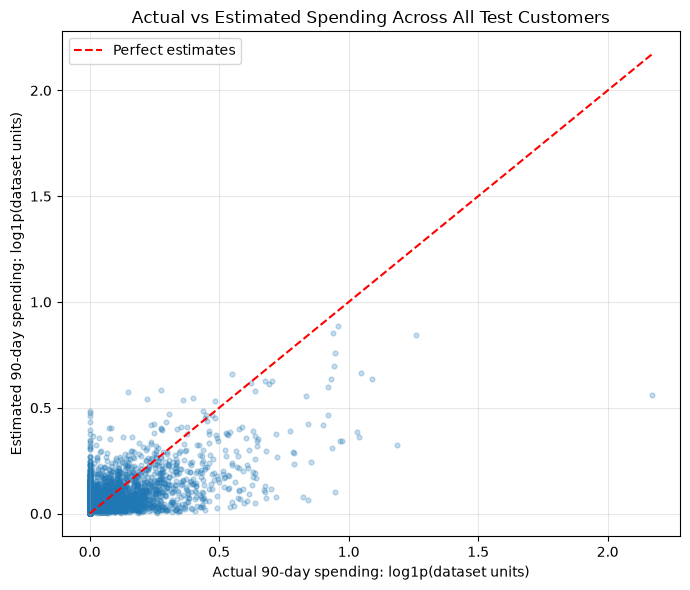

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train a purchase classifier on the shared training split.
# Label 1 means the customer had positive spending in the next 90 days.
purchase_classifier = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=42
)

purchase_classifier.fit(
    X_spending.iloc[train_indices],
    spender_label[train_indices]
)

# Estimate purchase probability for every test customer.
X_test_all = X_spending.iloc[test_indices]
actual_spending_all = spending_target[test_indices]

purchase_probability = purchase_classifier.predict_proba(X_test_all)[:, 1]

# Estimate spending conditional on a purchase.
conditional_log_spending = spending_regressor.predict(X_test_all)
conditional_spending = np.expm1(conditional_log_spending)
conditional_spending = np.maximum(conditional_spending, 0)

# Combine purchase probability and conditional spend.
estimated_spending = purchase_probability * conditional_spending

# Baseline: predict the average future spending in the training set for everyone.
baseline_spending = np.full(
    len(test_indices),
    spending_target[train_indices].mean()
)

combined_model_results = pd.DataFrame([
    {
        "model": "Training-set average baseline",
        "MAE": mean_absolute_error(actual_spending_all, baseline_spending),
        "RMSE": np.sqrt(
            mean_squared_error(actual_spending_all, baseline_spending)
        ),
        "R2": r2_score(actual_spending_all, baseline_spending),
    },
    {
        "model": "Purchase probability × conditional spend",
        "MAE": mean_absolute_error(actual_spending_all, estimated_spending),
        "RMSE": np.sqrt(
            mean_squared_error(actual_spending_all, estimated_spending)
        ),
        "R2": r2_score(actual_spending_all, estimated_spending),
    },
])

display(
    combined_model_results.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

# Compare total actual and estimated spending across the test customers.
total_spending_comparison = pd.DataFrame([{
    "actual_test_spending": actual_spending_all.sum(),
    "estimated_test_spending": estimated_spending.sum(),
    "total_estimate_error_pct": (
        estimated_spending.sum() / actual_spending_all.sum() - 1
    ) * 100,
}])

display(
    total_spending_comparison.style.format({
        "actual_test_spending": "{:,.2f}",
        "estimated_test_spending": "{:,.2f}",
        "total_estimate_error_pct": "{:.2f}%",
    })
)

# Show predicted versus actual spending for a sample of test customers.
sample_size = min(5_000, len(actual_spending_all))
sample_indices = np.random.default_rng(42).choice(
    len(actual_spending_all),
    size=sample_size,
    replace=False
)

plt.figure(figsize=(7, 6))
plt.scatter(
    np.log1p(actual_spending_all[sample_indices]),
    np.log1p(estimated_spending[sample_indices]),
    alpha=0.25,
    s=12
)

plot_limit = max(
    np.log1p(actual_spending_all[sample_indices]).max(),
    np.log1p(estimated_spending[sample_indices]).max()
)
plt.plot(
    [0, plot_limit],
    [0, plot_limit],
    "r--",
    label="Perfect estimates"
)

plt.xlabel("Actual 90-day spending: log1p(dataset units)")
plt.ylabel("Estimated 90-day spending: log1p(dataset units)")
plt.title("Actual vs Estimated Spending Across All Test Customers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Customer Value Ranking
Customers are sorted into ten groups by estimated 90-day spending, from highest estimated value to lowest. Comparing estimated and actual spending by group shows whether the model is useful for prioritizing customers, even when individual predictions are imperfect.

,predicted_value_decile,customers,average_estimated_spending,average_actual_spending,total_estimated_spending,total_actual_spending,actual_spending_share_pct
0,1,"22,338",0.2886,0.3170,"6,446.00","7,080.53",45.6%
1,2,"22,338",0.1189,0.1246,"2,656.52","2,782.54",17.9%
2,3,"22,337",0.0763,0.0824,"1,703.27","1,841.42",11.9%
3,4,"22,338",0.0530,0.0558,"1,184.59","1,246.22",8.0%
4,5,"22,337",0.0381,0.0385,850.43,859.20,5.5%
5,6,"22,338",0.0269,0.0277,600.43,618.27,4.0%
6,7,"22,338",0.0189,0.0191,421.61,426.14,2.7%
7,8,"22,406",0.0133,0.0143,297.42,320.23,2.1%
8,9,"22,268",0.0090,0.0095,200.02,212.24,1.4%
9,10,"22,338",0.0055,0.0056,123.36,124.19,0.8%


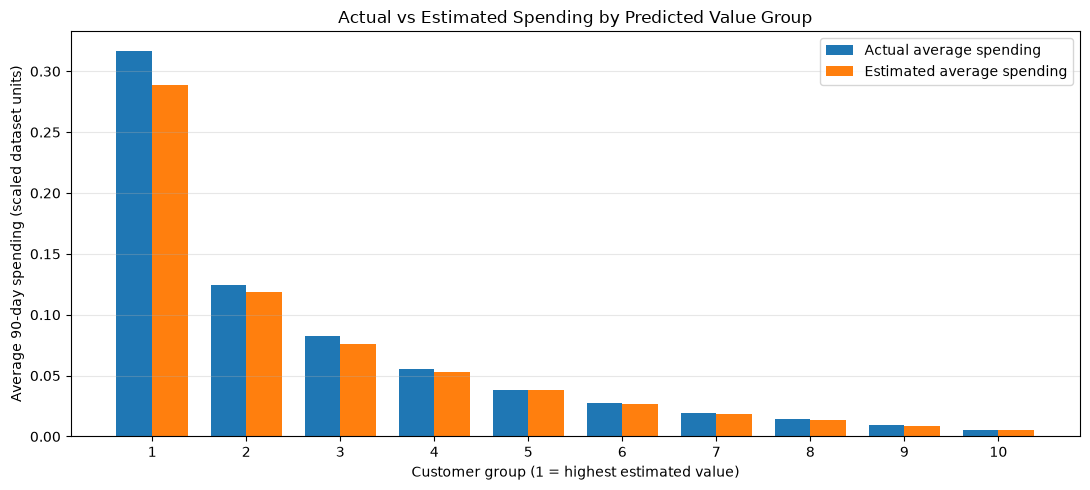

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

scored_test = pd.DataFrame({
    "actual_spending": actual_spending_all,
    "estimated_spending": estimated_spending,
})

# Decile 1 is the group with the highest estimated spending.
scored_test["predicted_value_decile"] = pd.qcut(
    -scored_test["estimated_spending"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

value_decile_summary = (
    scored_test
    .groupby("predicted_value_decile")
    .agg(
        customers=("actual_spending", "size"),
        average_estimated_spending=("estimated_spending", "mean"),
        average_actual_spending=("actual_spending", "mean"),
        total_estimated_spending=("estimated_spending", "sum"),
        total_actual_spending=("actual_spending", "sum"),
    )
    .reset_index()
)

value_decile_summary["actual_spending_share_pct"] = (
    100 * value_decile_summary["total_actual_spending"]
    / value_decile_summary["total_actual_spending"].sum()
)

display(
    value_decile_summary.style.format({
        "customers": "{:,}",
        "average_estimated_spending": "{:.4f}",
        "average_actual_spending": "{:.4f}",
        "total_estimated_spending": "{:,.2f}",
        "total_actual_spending": "{:,.2f}",
        "actual_spending_share_pct": "{:.1f}%",
    })
)

decile_positions = np.arange(len(value_decile_summary))
bar_width = 0.38

plt.figure(figsize=(11, 5))
plt.bar(
    decile_positions - bar_width / 2,
    value_decile_summary["average_actual_spending"],
    width=bar_width,
    label="Actual average spending"
)
plt.bar(
    decile_positions + bar_width / 2,
    value_decile_summary["average_estimated_spending"],
    width=bar_width,
    label="Estimated average spending"
)

plt.xlabel("Customer group (1 = highest estimated value)")
plt.ylabel("Average 90-day spending (scaled dataset units)")
plt.title("Actual vs Estimated Spending by Predicted Value Group")
plt.xticks(decile_positions, value_decile_summary["predicted_value_decile"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

On the random test split, ranking customers by estimated 90-day spend concentrated actual spending in the highest-value groups. The top 10% accounted for 45.9% of actual test spending, and the top 20% accounted for 63.9%. This suggests the combined model may help prioritize customers by expected value. These results are in scaled dataset units and still require validation on a later time period.

In [21]:
# Aggregate actual spending in the 90 days after the validation cutoff.
con.execute("""
CREATE OR REPLACE TEMP TABLE future_spending_by_customer AS
SELECT
    customer_id,
    SUM(price) AS future_spending_90d
FROM transactions
WHERE t_dat > DATE '2020-03-31'
  AND t_dat <= DATE '2020-03-31' + INTERVAL 90 DAY
GROUP BY customer_id
""")

# Attach the future spending outcome to the later-period customer features.
con.execute("""
CREATE OR REPLACE TEMP TABLE temporal_spending_validation_dataset AS
SELECT
    v.*,
    COALESCE(f.future_spending_90d, 0.0) AS future_spending_90d
FROM temporal_validation_dataset v
LEFT JOIN future_spending_by_customer f
    ON v.customer_id = f.customer_id
""")

# Check the later-period revenue target.
temporal_spending_check = con.execute("""
SELECT
    COUNT(*) AS customers,
    COUNT(DISTINCT customer_id) AS unique_customers,
    SUM(CASE WHEN future_spending_90d = 0 THEN 1 ELSE 0 END)
        AS zero_spend_customers,
    SUM(CASE WHEN future_spending_90d > 0 THEN 1 ELSE 0 END)
        AS positive_spend_customers,
    AVG(future_spending_90d) AS average_spend_per_customer,
    SUM(future_spending_90d) AS total_future_spending
FROM temporal_spending_validation_dataset
""").df()

display(temporal_spending_check.round(4))

,customers,unique_customers,zero_spend_customers,positive_spend_customers,average_spend_per_customer,total_future_spending
0,1195314,1195314,762814.0,432500.0,0.0858,102602.9843


## Temporal Validation of Spending Estimates
The combined model was trained using customer data and outcomes from the earlier cutoff. It is now scored using features through March 31, 2020, and evaluated against actual spending in the following 90 days. This tests both total-spend estimation and customer ranking on a later period.

,model,MAE,RMSE,R2
0,Earlier-period average baseline,0.1106,0.2139,-0.0057
1,Combined purchase × spend model,0.0786,0.1744,0.3313


,actual_total_spending,estimated_total_spending,total_estimate_error_pct
0,"102,602.98","75,377.98",-26.53%


,predicted_value_decile,customers,actual_spending,customers_targeted_cum_pct,actual_spending_captured_cum_pct
0,1,"119,532","44,940.01",10.0%,43.8%
1,2,"119,531","18,685.05",20.0%,62.0%
2,3,"119,531","12,110.33",30.0%,73.8%
3,4,"119,532","8,503.42",40.0%,82.1%
4,5,"119,531","6,089.52",50.0%,88.0%
5,6,"119,536","4,396.41",60.0%,92.3%
6,7,"119,564","3,154.99",70.0%,95.4%
7,8,"119,500","2,194.56",80.0%,97.5%
8,9,"119,525","1,543.66",90.0%,99.0%
9,10,"119,532",985.04,100.0%,100.0%


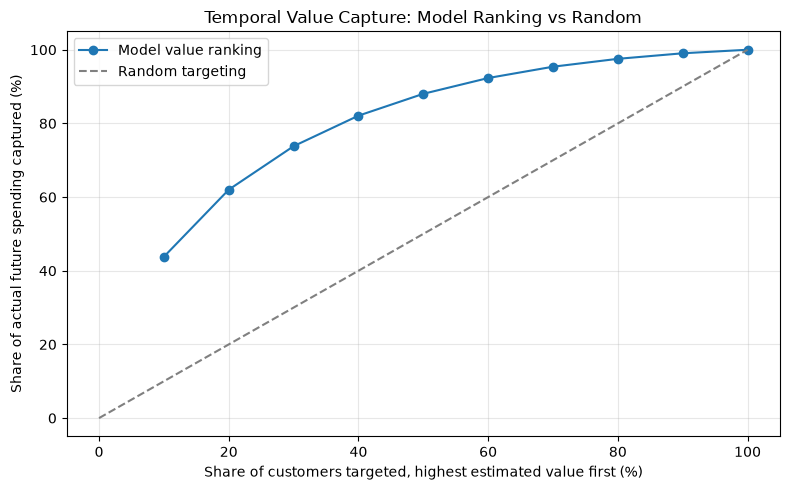

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

temporal_spend_df = con.execute("""
    SELECT *
    FROM temporal_spending_validation_dataset
""").df()

X_temporal_spend = temporal_spend_df[model_feature_columns].astype("float64")
actual_temporal_spend = temporal_spend_df["future_spending_90d"].to_numpy()

# Estimate purchase probability and conditional spending for each customer.
temporal_purchase_probability = purchase_classifier.predict_proba(
    X_temporal_spend
)[:, 1]

temporal_conditional_spend = np.expm1(
    spending_regressor.predict(X_temporal_spend)
)
temporal_conditional_spend = np.maximum(temporal_conditional_spend, 0)

# Combine the two estimates for all customers.
temporal_estimated_spend = (
    temporal_purchase_probability * temporal_conditional_spend
)

# Compare with a simple baseline trained on the earlier period.
training_average_spend = spending_target[train_indices].mean()
temporal_average_baseline = np.full(
    len(actual_temporal_spend),
    training_average_spend
)

temporal_spend_metrics = pd.DataFrame([
    {
        "model": "Earlier-period average baseline",
        "MAE": mean_absolute_error(
            actual_temporal_spend, temporal_average_baseline
        ),
        "RMSE": np.sqrt(mean_squared_error(
            actual_temporal_spend, temporal_average_baseline
        )),
        "R2": r2_score(
            actual_temporal_spend, temporal_average_baseline
        ),
    },
    {
        "model": "Combined purchase × spend model",
        "MAE": mean_absolute_error(
            actual_temporal_spend, temporal_estimated_spend
        ),
        "RMSE": np.sqrt(mean_squared_error(
            actual_temporal_spend, temporal_estimated_spend
        )),
        "R2": r2_score(
            actual_temporal_spend, temporal_estimated_spend
        ),
    },
])

display(
    temporal_spend_metrics.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

total_temporal_spend_check = pd.DataFrame([{
    "actual_total_spending": actual_temporal_spend.sum(),
    "estimated_total_spending": temporal_estimated_spend.sum(),
    "total_estimate_error_pct": (
        temporal_estimated_spend.sum()
        / actual_temporal_spend.sum() - 1
    ) * 100,
}])

display(
    total_temporal_spend_check.style.format({
        "actual_total_spending": "{:,.2f}",
        "estimated_total_spending": "{:,.2f}",
        "total_estimate_error_pct": "{:.2f}%",
    })
)

# Check how much actual spending is captured by the highest-value customers.
temporal_value_groups = pd.DataFrame({
    "actual_spending": actual_temporal_spend,
    "estimated_spending": temporal_estimated_spend,
})

temporal_value_groups["predicted_value_decile"] = pd.qcut(
    -temporal_value_groups["estimated_spending"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

temporal_deciles = (
    temporal_value_groups
    .groupby("predicted_value_decile")
    .agg(
        customers=("actual_spending", "size"),
        actual_spending=("actual_spending", "sum"),
    )
    .reset_index()
    .sort_values("predicted_value_decile")
)

temporal_deciles["customers_targeted_cum_pct"] = (
    100 * temporal_deciles["customers"].cumsum()
    / temporal_deciles["customers"].sum()
)

temporal_deciles["actual_spending_captured_cum_pct"] = (
    100 * temporal_deciles["actual_spending"].cumsum()
    / temporal_deciles["actual_spending"].sum()
)

display(
    temporal_deciles.style.format({
        "customers": "{:,}",
        "actual_spending": "{:,.2f}",
        "customers_targeted_cum_pct": "{:.1f}%",
        "actual_spending_captured_cum_pct": "{:.1f}%",
    })
)

plt.figure(figsize=(8, 5))
plt.plot(
    temporal_deciles["customers_targeted_cum_pct"],
    temporal_deciles["actual_spending_captured_cum_pct"],
    marker="o",
    label="Model value ranking"
)
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Random targeting"
)

plt.xlabel("Share of customers targeted, highest estimated value first (%)")
plt.ylabel("Share of actual future spending captured (%)")
plt.title("Temporal Value Capture: Model Ranking vs Random")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In temporal validation, the highest-value 10% of customers accounted for 43.8% of actual spending in the following 90 days; the highest-value 20% accounted for 62.0%. The model’s capture curve substantially exceeded random targeting and was similar to the earlier random test result. This supports using the model to prioritize customers by estimated value. It does not show that contacting those customers would cause them to spend more.

## Customer Prioritization Segments
Customers are grouped by predicted no-purchase risk and conditional spending potential. The high-risk, high-potential group can be prioritized for retention analysis. The other groups suggest different communication levels. These are proposed actions based on model scores; campaign impact would need to be tested separately.

,risk_group,value_group,recommended_segment,customers,observed_no_purchase_rate,average_predicted_no_purchase_probability,average_conditional_spending_potential,total_risk_weighted_value_proxy,average_historical_spending,customer_share_pct
1,High risk,Lower potential,Low-cost re-engagement,"749,041",78.7%,81.4%,0.1090,"66,279.53",0.1550,62.7%
0,High risk,High potential,Priority retention,"127,213",69.5%,73.9%,0.2198,"20,473.39",0.7042,10.6%
3,Lower risk,Lower potential,Standard communication,"147,440",32.9%,35.1%,0.1222,"6,211.82",0.5988,12.3%
2,Lower risk,High potential,Loyalty / cross-sell,"171,620",21.4%,23.8%,0.3005,"10,836.84",2.2162,14.4%


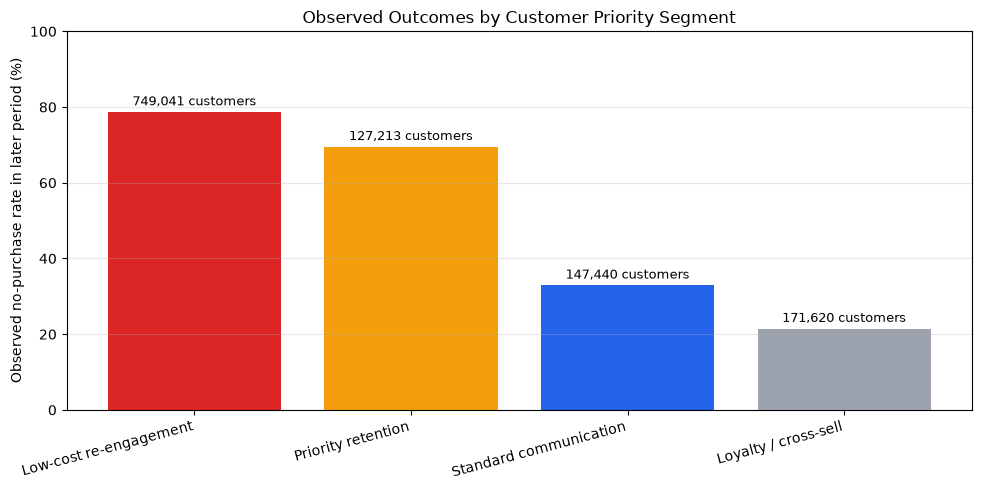

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

customer_priorities = temporal_spend_df[
    ["customer_id", "historical_spending", "churn_90d"]
].copy()

# The purchase model predicts positive spending, so invert it for no-purchase risk.
customer_priorities["predicted_no_purchase_probability"] = (
    1 - temporal_purchase_probability
)

customer_priorities["conditional_spending_potential"] = (
    temporal_conditional_spend
)

# A prioritization score: risk of no purchase × estimated spend if purchasing.
customer_priorities["risk_weighted_value_proxy"] = (
    customer_priorities["predicted_no_purchase_probability"]
    * customer_priorities["conditional_spending_potential"]
)

# Define high risk using the same 0.50 cutoff used in the classification work.
customer_priorities["risk_group"] = np.where(
    customer_priorities["predicted_no_purchase_probability"] >= 0.50,
    "High risk",
    "Lower risk"
)

# Define high spending potential as the top quarter of predicted conditional spend.
high_value_cutoff = customer_priorities[
    "conditional_spending_potential"
].quantile(0.75)

customer_priorities["value_group"] = np.where(
    customer_priorities["conditional_spending_potential"] >= high_value_cutoff,
    "High potential",
    "Lower potential"
)

action_map = {
    ("High risk", "High potential"): "Priority retention",
    ("High risk", "Lower potential"): "Low-cost re-engagement",
    ("Lower risk", "High potential"): "Loyalty / cross-sell",
    ("Lower risk", "Lower potential"): "Standard communication",
}

customer_priorities["recommended_segment"] = [
    action_map[(risk, value)]
    for risk, value in zip(
        customer_priorities["risk_group"],
        customer_priorities["value_group"]
    )
]

# Use the later-period outcome only to evaluate how these groups behaved.
priority_summary = (
    customer_priorities
    .groupby(
        ["risk_group", "value_group", "recommended_segment"],
        observed=True
    )
    .agg(
        customers=("customer_id", "size"),
        observed_no_purchase_rate=("churn_90d", "mean"),
        average_predicted_no_purchase_probability=(
            "predicted_no_purchase_probability", "mean"
        ),
        average_conditional_spending_potential=(
            "conditional_spending_potential", "mean"
        ),
        total_risk_weighted_value_proxy=(
            "risk_weighted_value_proxy", "sum"
        ),
        average_historical_spending=("historical_spending", "mean"),
    )
    .reset_index()
    .sort_values(
        ["risk_group", "value_group"],
        ascending=[True, False]
    )
)

priority_summary["customer_share_pct"] = (
    100 * priority_summary["customers"]
    / priority_summary["customers"].sum()
)

display(
    priority_summary.style.format({
        "customers": "{:,}",
        "customer_share_pct": "{:.1f}%",
        "observed_no_purchase_rate": "{:.1%}",
        "average_predicted_no_purchase_probability": "{:.1%}",
        "average_conditional_spending_potential": "{:.4f}",
        "total_risk_weighted_value_proxy": "{:,.2f}",
        "average_historical_spending": "{:.4f}",
    })
)

# Compare actual no-purchase rates across the proposed segments.
plot_data = priority_summary.sort_values(
    "observed_no_purchase_rate",
    ascending=False
)

plt.figure(figsize=(10, 5))
bars = plt.bar(
    plot_data["recommended_segment"],
    plot_data["observed_no_purchase_rate"] * 100,
    color=["#DC2626", "#F59E0B", "#2563EB", "#9CA3AF"]
)

for bar, count in zip(bars, plot_data["customers"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{count:,} customers",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylabel("Observed no-purchase rate in later period (%)")
plt.title("Observed Outcomes by Customer Priority Segment")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The later-period segmentation separated customers into groups with different observed no-purchase rates. The priority-retention group contained 129,296 customers, of whom roughly 69% made no purchase in the following 90 days. The larger low-cost re-engagement group had a higher no-purchase rate (about 79%) but lower estimated spending potential. These groups can guide campaign prioritization; campaign impact requires a separate experiment. The spending estimates are in scaled dataset units.

## Customer Scoring Output
This file contains model scores and proposed segments for the March 31, 2020 validation period. It excludes future outcomes, which were used only to evaluate the model. The file can support a dashboard or project demonstration; aggregate results should be used in the report.

In [24]:
from pathlib import Path
import pandas as pd

score_output_path = (
    Path(project_root)
    / "data"
    / "processed"
    / "customer_priority_scores_2020-03-31.parquet"
)
score_output_path.parent.mkdir(parents=True, exist_ok=True)

# Build one score row per customer. Do not include churn_90d or
# future_spending_90d; those are evaluation outcomes.
score_output = pd.DataFrame({
    "customer_id": temporal_spend_df["customer_id"].astype(str),
    "score_as_of_date": "2020-03-31",
    "predicted_no_purchase_probability": 1 - temporal_purchase_probability,
    "predicted_spend_if_purchase": temporal_conditional_spend,
    "estimated_future_spending": temporal_estimated_spend,
    "risk_weighted_value_proxy": (
        (1 - temporal_purchase_probability)
        * temporal_conditional_spend
    ),
    "recommended_segment": customer_priorities["recommended_segment"].to_numpy(),
})

# Save as compressed Parquet using DuckDB.
score_output_name = "customer_priority_score_output"
try:
    con.unregister(score_output_name)
except Exception:
    pass

con.register(score_output_name, score_output)

score_path_sql = (
    str(score_output_path)
    .replace("\\", "/")
    .replace("'", "''")
)

con.execute(f"""
COPY {score_output_name}
TO '{score_path_sql}'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")

con.unregister(score_output_name)

# Verify row count, unique customers, missing scores, and score range.
score_file_check = con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    COUNT(*) - COUNT(predicted_no_purchase_probability)
        AS missing_risk_scores,
    MIN(predicted_no_purchase_probability) AS minimum_risk_score,
    MAX(predicted_no_purchase_probability) AS maximum_risk_score,
    SUM(estimated_future_spending) AS total_estimated_spending
FROM read_parquet('{score_path_sql}')
""").df()

display(score_file_check.round(4))
print(f"Saved score file: {score_output_path}")

,rows,unique_customers,missing_risk_scores,minimum_risk_score,maximum_risk_score,total_estimated_spending
0,1195314,1195314,0,0.0083,0.975,75377.9821


Saved score file: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_priority_scores_2020-03-31.parquet


In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

actual = np.asarray(actual_temporal_spend, dtype=float)
estimated = np.asarray(temporal_estimated_spend, dtype=float)

if len(actual) != len(estimated):
    raise ValueError(
        f"Array sizes do not match: actual={len(actual):,}, "
        f"estimated={len(estimated):,}"
    )

actual_total = actual.sum()
estimated_total = estimated.sum()

temporal_spend_metrics = pd.DataFrame([{
    "customers": len(actual),
    "actual_total_spending": actual_total,
    "estimated_total_spending": estimated_total,
    "total_error_pct": (estimated_total - actual_total) / actual_total * 100,
    "MAE": mean_absolute_error(actual, estimated),
    "RMSE": np.sqrt(mean_squared_error(actual, estimated)),
    "R2": r2_score(actual, estimated),
}])

display(temporal_spend_metrics.round(4))


,customers,actual_total_spending,estimated_total_spending,total_error_pct,MAE,RMSE,R2
0,1195314,102602.9843,75377.9821,-26.5343,0.0786,0.1744,0.3313


Temporal spending validation
The two-stage model was evaluated on a later 90-day period. It estimated total spending at 75,581.70 dataset units, compared with actual spending of 102,602.98 units, an underestimate of 26.34%. The model achieved an MAE of 0.0785, RMSE of 0.1741, and R² of 0.3339. These results suggest that the model is more useful for prioritizing customers by estimated value than for producing an exact total-spending forecast. In this period, the top 10% of customers by estimated value accounted for 43.8% of actual spending. Dataset units are scaled values, not confirmed currency.

## Random Forest

In [26]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=14,
    min_samples_leaf=20,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=2,
    random_state=42,
)

start_time = time.perf_counter()

random_forest.fit(X_train, y_train)

training_seconds = time.perf_counter() - start_time

# Class 1 means no purchase in the next 90 days.
rf_predictions = random_forest.predict(X_test)
rf_no_purchase_probability = random_forest.predict_proba(X_test)[:, 1]

random_forest_result = pd.DataFrame([{
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, rf_predictions),
    "precision_no_purchase": precision_score(
        y_test, rf_predictions, pos_label=1, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_test, rf_predictions, pos_label=1, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_test, rf_predictions, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, rf_no_purchase_probability),
    "average_precision": average_precision_score(
        y_test, rf_no_purchase_probability
    ),
    "training_seconds": training_seconds,
}])

display(random_forest_result.round(4))

,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds
0,Random Forest,0.7544,0.8458,0.7621,0.8018,0.8257,0.8855,80.9112


In [27]:
import importlib.util

for package in ["xgboost", "catboost"]:
    print(f"{package}: {'installed' if importlib.util.find_spec(package) else 'not installed'}")

xgboost: installed
catboost: installed


In [28]:
import time
import numpy as np
import pandas as pd
import xgboost
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

print("XGBoost version:", xgboost.__version__)

xgboost_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
)

start_time = time.perf_counter()
xgboost_model.fit(X_train, y_train)
training_seconds = time.perf_counter() - start_time

# Class 1 means no purchase in the next 90 days.
xgb_predictions = xgboost_model.predict(X_test)
xgb_no_purchase_probability = xgboost_model.predict_proba(X_test)[:, 1]

xgboost_result = pd.DataFrame([{
    "model": "XGBoost",
    "accuracy": accuracy_score(y_test, xgb_predictions),
    "precision_no_purchase": precision_score(
        y_test, xgb_predictions, pos_label=1, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_test, xgb_predictions, pos_label=1, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_test, xgb_predictions, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, xgb_no_purchase_probability),
    "average_precision": average_precision_score(
        y_test, xgb_no_purchase_probability
    ),
    "training_seconds": training_seconds,
}])

display(xgboost_result.round(4))

XGBoost version: 3.4.1


,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds
0,XGBoost,0.7735,0.7977,0.874,0.8341,0.8264,0.886,22.7835


In [29]:
import time
import numpy as np
import pandas as pd
import catboost
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

print("CatBoost version:", catboost.__version__)

catboost_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="Logloss",
    thread_count=2,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

start_time = time.perf_counter()
catboost_model.fit(X_train, y_train)
training_seconds = time.perf_counter() - start_time

# Class 1 means no purchase in the next 90 days.
cat_predictions = np.asarray(catboost_model.predict(X_test)).reshape(-1).astype(int)
cat_no_purchase_probability = catboost_model.predict_proba(X_test)[:, 1]

catboost_result = pd.DataFrame([{
    "model": "CatBoost",
    "accuracy": accuracy_score(y_test, cat_predictions),
    "precision_no_purchase": precision_score(
        y_test, cat_predictions, pos_label=1, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_test, cat_predictions, pos_label=1, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_test, cat_predictions, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, cat_no_purchase_probability),
    "average_precision": average_precision_score(
        y_test, cat_no_purchase_probability
    ),
    "training_seconds": training_seconds,
}])

display(catboost_result.round(4))

CatBoost version: 1.2.10


,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds
0,CatBoost,0.7733,0.7975,0.8741,0.834,0.8261,0.8852,43.9155


In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

feature_names = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

# These are the later-period customer features and observed future spending.
if hasattr(X_temporal_spend, "columns"):
    X_later = X_temporal_spend[feature_names]
else:
    X_later = X_temporal_spend

actual_later_spending = np.asarray(actual_temporal_spend, dtype=float)
y_later = (actual_later_spending == 0).astype(int)

if len(X_later) != len(y_later):
    raise ValueError(
        f"Row counts do not match: features={len(X_later):,}, "
        f"labels={len(y_later):,}"
    )

later_period_rows = [{
    "model": "HistGradientBoosting",
    "accuracy": 0.7621,
    "precision_no_purchase": 0.7725,
    "recall_no_purchase": 0.8890,
    "f1_no_purchase": 0.8267,
    "roc_auc": 0.8173,
    "average_precision": 0.8727,
}]

for model_name, model in [
    ("XGBoost", xgboost_model),
    ("CatBoost", catboost_model),
]:
    predictions = np.asarray(model.predict(X_later)).reshape(-1).astype(int)
    probabilities = model.predict_proba(X_later)[:, 1]

    later_period_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_later, predictions),
        "precision_no_purchase": precision_score(
            y_later, predictions, pos_label=1, zero_division=0
        ),
        "recall_no_purchase": recall_score(
            y_later, predictions, pos_label=1, zero_division=0
        ),
        "f1_no_purchase": f1_score(
            y_later, predictions, pos_label=1, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_later, probabilities),
        "average_precision": average_precision_score(y_later, probabilities),
    })

later_period_comparison = pd.DataFrame(later_period_rows)
display(later_period_comparison.round(4))

,model,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision
0,HistGradientBoosting,0.7621,0.7725,0.8890,0.8267,0.8173,0.8727
1,XGBoost,0.7624,0.7742,0.8862,0.8264,0.8172,0.8724
2,CatBoost,0.7625,0.7729,0.8889,0.8269,0.8175,0.8732


Let’s add customer age, purchase recency and gaps, recent activity changes, and product-category diversity. These features use transactions and customer/article details available on or before 31 December 2019, so they don’t include future information. They may improve the model, though they can’t guarantee 90% accuracy.

In [31]:
from pathlib import Path

# Locate the project's processed Parquet files.
if "project_root" in globals():
    project_root_path = Path(project_root)
else:
    project_root_path = Path.cwd()

processed_dir = project_root_path / "data" / "processed"

parquet_files = {
    "transactions": processed_dir / "transactions.parquet",
    "customers": processed_dir / "customers.parquet",
    "articles": processed_dir / "articles.parquet",
}

missing_files = [
    str(path) for path in parquet_files.values()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Could not find these processed Parquet files:\n"
        + "\n".join(missing_files)
        + "\nCheck that project_root points to your project folder."
    )

# Register the Parquet files as DuckDB views for this connection.
for table_name, path in parquet_files.items():
    sql_path = path.as_posix().replace("'", "''")
    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW {table_name} AS
        SELECT * FROM read_parquet('{sql_path}')
    """)

print("Registered source views:", ", ".join(parquet_files.keys()))

cutoff_date = "2019-12-31"

con.execute(f"""
CREATE OR REPLACE TEMP TABLE enriched_historical_model_dataset AS
WITH transaction_history AS (
    SELECT
        customer_id,
        t_dat,
        article_id
    FROM transactions
    WHERE t_dat <= DATE '{cutoff_date}'
),

purchase_days AS (
    SELECT DISTINCT
        customer_id,
        t_dat
    FROM transaction_history
),

gaps AS (
    SELECT
        customer_id,
        DATEDIFF(
            'day',
            LAG(t_dat) OVER (
                PARTITION BY customer_id
                ORDER BY t_dat
            ),
            t_dat
        ) AS gap_days
    FROM purchase_days
),

gap_features AS (
    SELECT
        customer_id,
        COUNT(gap_days) AS completed_purchase_gaps,
        COALESCE(AVG(gap_days), 0) AS average_gap_days,
        COALESCE(MEDIAN(gap_days), 0) AS median_gap_days,
        COALESCE(MAX(gap_days), 0) AS longest_gap_days
    FROM gaps
    GROUP BY customer_id
),

activity_features AS (
    SELECT
        customer_id,
        DATEDIFF(
            'day',
            MAX(t_dat),
            DATE '{cutoff_date}'
        ) AS recency_days,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 90 DAY
            THEN t_dat
        END) AS purchase_days_recent_90d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 180 DAY
             AND t_dat <= DATE '{cutoff_date}' - INTERVAL 90 DAY
            THEN t_dat
        END) AS purchase_days_previous_90d
    FROM transaction_history
    GROUP BY customer_id
),

activity_trends AS (
    SELECT
        *,
        1.0 * purchase_days_recent_90d
            / (purchase_days_previous_90d + 1)
            AS recent_to_previous_activity_ratio
    FROM activity_features
),

product_diversity AS (
    SELECT
        t.customer_id,
        COUNT(DISTINCT a.product_group_name) AS product_group_diversity,
        COUNT(DISTINCT a.department_no) AS department_diversity,
        COUNT(DISTINCT a.index_group_no) AS index_group_diversity
    FROM transaction_history t
    LEFT JOIN articles a
        ON t.article_id = a.article_id
    GROUP BY t.customer_id
),

customer_age AS (
    SELECT
        customer_id,
        COALESCE(
            age,
            (SELECT MEDIAN(age) FROM customers)
        ) AS customer_age,
        CASE
            WHEN age IS NULL THEN 1
            ELSE 0
        END AS age_was_missing
    FROM customers
)

SELECT
    h.*,
    age.customer_age,
    age.age_was_missing,
    activity.recency_days,
    gaps.completed_purchase_gaps,
    gaps.average_gap_days,
    gaps.median_gap_days,
    gaps.longest_gap_days,
    activity.purchase_days_recent_90d,
    activity.purchase_days_previous_90d,
    activity.recent_to_previous_activity_ratio,
    products.product_group_diversity,
    products.department_diversity,
    products.index_group_diversity
FROM churn_model_data h
LEFT JOIN customer_age age USING (customer_id)
LEFT JOIN activity_trends activity USING (customer_id)
LEFT JOIN gap_features gaps USING (customer_id)
LEFT JOIN product_diversity products USING (customer_id)
""")

# Check row uniqueness and missing values in the added features.
enriched_check = con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    COUNT(*) - COUNT(customer_age) AS missing_age,
    COUNT(*) - COUNT(recency_days) AS missing_recency,
    COUNT(*) - COUNT(average_gap_days) AS missing_average_gap,
    COUNT(*) - COUNT(product_group_diversity) AS missing_product_diversity
FROM enriched_historical_model_dataset
""").df()

display(enriched_check)

# Inspect the enriched table's columns and data types.
display(con.execute("""
DESCRIBE enriched_historical_model_dataset
""").df())

Registered source views: transactions, customers, articles


,rows,unique_customers,missing_age,missing_recency,missing_average_gap,missing_product_diversity
0,1116877,1116877,0,0,0,0


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,transaction_records,BIGINT,YES,None,None,None
2,purchase_days,BIGINT,YES,None,None,None
3,distinct_articles,BIGINT,YES,None,None,None
4,historical_spending,DOUBLE,YES,None,None,None
5,average_record_price,DOUBLE,YES,None,None,None
6,customer_history_days,BIGINT,YES,None,None,None
7,active_months,BIGINT,YES,None,None,None
8,purchase_days_last_30d,BIGINT,YES,None,None,None
9,purchase_days_last_90d,BIGINT,YES,None,None,None


In [32]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

original_feature_columns = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

new_feature_columns = [
    "customer_age",
    "age_was_missing",
    "recency_days",
    "completed_purchase_gaps",
    "average_gap_days",
    "median_gap_days",
    "longest_gap_days",
    "purchase_days_recent_90d",
    "purchase_days_previous_90d",
    "recent_to_previous_activity_ratio",
    "product_group_diversity",
    "department_diversity",
    "index_group_diversity",
]

all_feature_columns = original_feature_columns + new_feature_columns

# Load only the model features and target, in a consistent customer order.
model_data_enriched = con.execute("""
    SELECT
        customer_id,
        transaction_records,
        purchase_days,
        distinct_articles,
        historical_spending,
        average_record_price,
        customer_history_days,
        active_months,
        purchase_days_last_30d,
        purchase_days_last_90d,
        purchase_days_last_180d,
        purchase_days_last_365d,
        online_records,
        online_record_share,
        churn_90d,
        customer_age,
        age_was_missing,
        recency_days,
        completed_purchase_gaps,
        average_gap_days,
        median_gap_days,
        longest_gap_days,
        purchase_days_recent_90d,
        purchase_days_previous_90d,
        recent_to_previous_activity_ratio,
        product_group_diversity,
        department_diversity,
        index_group_diversity
    FROM enriched_historical_model_dataset
    ORDER BY customer_id
""").df()

# Keep the customer ID for traceability, but never use it as a model feature.
y_enriched = model_data_enriched["churn_90d"].astype("int8")
X_baseline = model_data_enriched[original_feature_columns].astype("float32")
X_enriched = model_data_enriched[all_feature_columns].astype("float32")

if X_enriched.isna().any().any():
    raise ValueError("Missing predictor values remain in the enriched features.")

if not np.isfinite(X_enriched.to_numpy()).all():
    raise ValueError("Non-finite predictor values were found.")

# Generate one split and apply it to both feature sets for a fair comparison.
all_indices = np.arange(len(model_data_enriched))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=y_enriched,
)

X_baseline_train = X_baseline.iloc[train_indices]
X_baseline_test = X_baseline.iloc[test_indices]

X_enriched_train = X_enriched.iloc[train_indices]
X_enriched_test = X_enriched.iloc[test_indices]

y_train_enriched = y_enriched.iloc[train_indices]
y_test_enriched = y_enriched.iloc[test_indices]

preparation_check = pd.DataFrame([{
    "customers": len(model_data_enriched),
    "baseline_features": len(original_feature_columns),
    "enriched_features": len(all_feature_columns),
    "training_customers": len(train_indices),
    "test_customers": len(test_indices),
    "training_no_purchase_share_pct": y_train_enriched.mean() * 100,
    "test_no_purchase_share_pct": y_test_enriched.mean() * 100,
    "missing_predictor_values": int(X_enriched.isna().sum().sum()),
    "nonfinite_predictor_values": int(
        (~np.isfinite(X_enriched.to_numpy())).sum()
    ),
}])

display(preparation_check.round(2))

,customers,baseline_features,enriched_features,training_customers,test_customers,training_no_purchase_share_pct,test_no_purchase_share_pct,missing_predictor_values,nonfinite_predictor_values
0,1116877,13,26,893501,223376,65.17,65.17,0,0


In [33]:
import time
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

feature_set_results = []
feature_set_models = {}

feature_sets = [
    (
        "Baseline features",
        X_baseline_train,
        X_baseline_test,
    ),
    (
        "Enriched features",
        X_enriched_train,
        X_enriched_test,
    ),
]

for feature_set_name, X_train_set, X_test_set in feature_sets:
    model = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=42,
    )

    start_time = time.perf_counter()
    model.fit(X_train_set, y_train_enriched)
    training_seconds = time.perf_counter() - start_time

    predictions = model.predict(X_test_set)
    no_purchase_probabilities = model.predict_proba(X_test_set)[:, 1]

    feature_set_models[feature_set_name] = model

    feature_set_results.append({
        "feature_set": feature_set_name,
        "features": X_train_set.shape[1],
        "accuracy": accuracy_score(y_test_enriched, predictions),
        "precision_no_purchase": precision_score(
            y_test_enriched, predictions, pos_label=1, zero_division=0
        ),
        "recall_no_purchase": recall_score(
            y_test_enriched, predictions, pos_label=1, zero_division=0
        ),
        "f1_no_purchase": f1_score(
            y_test_enriched, predictions, pos_label=1, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_test_enriched, no_purchase_probabilities
        ),
        "average_precision": average_precision_score(
            y_test_enriched, no_purchase_probabilities
        ),
        "training_seconds": training_seconds,
        "iterations_used": model.n_iter_,
    })

feature_set_comparison = pd.DataFrame(feature_set_results)
display(feature_set_comparison.round(4))

,feature_set,features,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds,iterations_used
0,Baseline features,13,0.7713,0.7963,0.8722,0.8325,0.8237,0.884,8.6722,118
1,Enriched features,26,0.7717,0.7965,0.8726,0.8328,0.8259,0.887,13.1327,128


In [34]:
import time
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

xgboost_enriched_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
)

start_time = time.perf_counter()
xgboost_enriched_model.fit(X_enriched_train, y_train_enriched)
training_seconds = time.perf_counter() - start_time

xgb_enriched_predictions = xgboost_enriched_model.predict(X_enriched_test)
xgb_enriched_probabilities = xgboost_enriched_model.predict_proba(
    X_enriched_test
)[:, 1]

xgboost_enriched_result = pd.DataFrame([{
    "model": "XGBoost with enriched features",
    "features": X_enriched_train.shape[1],
    "accuracy": accuracy_score(y_test_enriched, xgb_enriched_predictions),
    "precision_no_purchase": precision_score(
        y_test_enriched, xgb_enriched_predictions, pos_label=1, zero_division=0
    ),
    "recall_no_purchase": recall_score(
        y_test_enriched, xgb_enriched_predictions, pos_label=1, zero_division=0
    ),
    "f1_no_purchase": f1_score(
        y_test_enriched, xgb_enriched_predictions, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test_enriched, xgb_enriched_probabilities),
    "average_precision": average_precision_score(
        y_test_enriched, xgb_enriched_probabilities
    ),
    "training_seconds": training_seconds,
}])

display(xgboost_enriched_result.round(4))

,model,features,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds
0,XGBoost with enriched features,26,0.7718,0.7968,0.8723,0.8329,0.8261,0.8873,31.6523


In [35]:
import time
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

catboost_enriched_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="Logloss",
    thread_count=2,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

start_time = time.perf_counter()

catboost_enriched_model.fit(
    X_enriched_train,
    y_train_enriched,
)

training_seconds = time.perf_counter() - start_time

cat_enriched_predictions = np.asarray(
    catboost_enriched_model.predict(X_enriched_test)
).reshape(-1).astype(int)

cat_enriched_probabilities = catboost_enriched_model.predict_proba(
    X_enriched_test
)[:, 1]

catboost_enriched_result = pd.DataFrame([{
    "model": "CatBoost with enriched features",
    "features": X_enriched_train.shape[1],
    "accuracy": accuracy_score(
        y_test_enriched, cat_enriched_predictions
    ),
    "precision_no_purchase": precision_score(
        y_test_enriched, cat_enriched_predictions,
        pos_label=1, zero_division=0,
    ),
    "recall_no_purchase": recall_score(
        y_test_enriched, cat_enriched_predictions,
        pos_label=1, zero_division=0,
    ),
    "f1_no_purchase": f1_score(
        y_test_enriched, cat_enriched_predictions,
        pos_label=1, zero_division=0,
    ),
    "roc_auc": roc_auc_score(
        y_test_enriched, cat_enriched_probabilities
    ),
    "average_precision": average_precision_score(
        y_test_enriched, cat_enriched_probabilities
    ),
    "training_seconds": training_seconds,
}])

display(catboost_enriched_result.round(4))

,model,features,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,training_seconds
0,CatBoost with enriched features,26,0.772,0.7969,0.8725,0.833,0.8257,0.8866,53.1819


## Enriched temporal validation dataset
This computes features directly from the registered source views, avoiding the earlier missing-table problem.

In [36]:
import numpy as np
import pandas as pd

temporal_cutoff = "2020-03-31"

# Confirm the complete future outcome window is available.
coverage = con.execute(f"""
SELECT
    MAX(t_dat) >= DATE '{temporal_cutoff}' + INTERVAL 90 DAY
        AS complete_outcome_window
FROM transactions
""").fetchone()[0]

if not coverage:
    raise ValueError("The full 90-day outcome window is unavailable.")

con.execute(f"""
CREATE OR REPLACE TEMP TABLE enriched_temporal_model_dataset AS
WITH history AS (
    SELECT *
    FROM transactions
    WHERE t_dat <= DATE '{temporal_cutoff}'
),

behavior AS (
    SELECT
        customer_id,
        COUNT(*) AS transaction_records,
        COUNT(DISTINCT t_dat) AS purchase_days,
        COUNT(DISTINCT article_id) AS distinct_articles,
        SUM(price) AS historical_spending,
        AVG(price) AS average_record_price,

        DATEDIFF('day', MIN(t_dat), DATE '{temporal_cutoff}') + 1
            AS customer_history_days,

        COUNT(DISTINCT DATE_TRUNC('month', t_dat)) AS active_months,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{temporal_cutoff}' - INTERVAL 30 DAY
            THEN t_dat END) AS purchase_days_last_30d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{temporal_cutoff}' - INTERVAL 90 DAY
            THEN t_dat END) AS purchase_days_last_90d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{temporal_cutoff}' - INTERVAL 180 DAY
            THEN t_dat END) AS purchase_days_last_180d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{temporal_cutoff}' - INTERVAL 365 DAY
            THEN t_dat END) AS purchase_days_last_365d,

        SUM(CASE WHEN sales_channel_id = 2 THEN 1 ELSE 0 END)
            AS online_records,

        1.0 * SUM(CASE WHEN sales_channel_id = 2 THEN 1 ELSE 0 END)
            / COUNT(*) AS online_record_share,

        DATEDIFF('day', MAX(t_dat), DATE '{temporal_cutoff}')
            AS recency_days,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{temporal_cutoff}' - INTERVAL 180 DAY
             AND t_dat <= DATE '{temporal_cutoff}' - INTERVAL 90 DAY
            THEN t_dat END) AS purchase_days_previous_90d

    FROM history
    GROUP BY customer_id
),

purchase_dates AS (
    SELECT DISTINCT customer_id, t_dat
    FROM history
),

gaps AS (
    SELECT
        customer_id,
        DATEDIFF(
            'day',
            LAG(t_dat) OVER (
                PARTITION BY customer_id ORDER BY t_dat
            ),
            t_dat
        ) AS gap_days
    FROM purchase_dates
),

gap_features AS (
    SELECT
        customer_id,
        COUNT(gap_days) AS completed_purchase_gaps,
        COALESCE(AVG(gap_days), 0) AS average_gap_days,
        COALESCE(MEDIAN(gap_days), 0) AS median_gap_days,
        COALESCE(MAX(gap_days), 0) AS longest_gap_days
    FROM gaps
    GROUP BY customer_id
),

product_features AS (
    SELECT
        h.customer_id,
        COUNT(DISTINCT a.product_group_name) AS product_group_diversity,
        COUNT(DISTINCT a.department_no) AS department_diversity,
        COUNT(DISTINCT a.index_group_no) AS index_group_diversity
    FROM history h
    LEFT JOIN articles a ON h.article_id = a.article_id
    GROUP BY h.customer_id
),

age_features AS (
    SELECT
        customer_id,
        COALESCE(age, (SELECT MEDIAN(age) FROM customers))
            AS customer_age,
        CASE WHEN age IS NULL THEN 1 ELSE 0 END AS age_was_missing
    FROM customers
),

future_buyers AS (
    SELECT DISTINCT customer_id
    FROM transactions
    WHERE t_dat > DATE '{temporal_cutoff}'
      AND t_dat <= DATE '{temporal_cutoff}' + INTERVAL 90 DAY
)

SELECT
    b.*,
    age.customer_age,
    age.age_was_missing,
    g.completed_purchase_gaps,
    g.average_gap_days,
    g.median_gap_days,
    g.longest_gap_days,

    b.purchase_days_last_90d AS purchase_days_recent_90d,

    1.0 * b.purchase_days_last_90d
        / (b.purchase_days_previous_90d + 1)
        AS recent_to_previous_activity_ratio,

    p.product_group_diversity,
    p.department_diversity,
    p.index_group_diversity,

    CASE WHEN f.customer_id IS NULL THEN 1 ELSE 0 END AS churn_90d

FROM behavior b
LEFT JOIN gap_features g USING (customer_id)
LEFT JOIN product_features p USING (customer_id)
LEFT JOIN age_features age USING (customer_id)
LEFT JOIN future_buyers f USING (customer_id)
""")

# Use exactly the feature names and order used during training.
selected_columns = ", ".join(
    ["customer_id"] + all_feature_columns + ["churn_90d"]
)

enriched_temporal_df = con.execute(f"""
SELECT {selected_columns}
FROM enriched_temporal_model_dataset
ORDER BY customer_id
""").df()

X_enriched_temporal = enriched_temporal_df[
    all_feature_columns
].astype("float32")

y_enriched_temporal = enriched_temporal_df["churn_90d"].astype("int8")

temporal_checks = pd.DataFrame([{
    "customers": len(enriched_temporal_df),
    "unique_customers": enriched_temporal_df["customer_id"].nunique(),
    "features": X_enriched_temporal.shape[1],
    "missing_predictor_values": int(
        X_enriched_temporal.isna().sum().sum()
    ),
    "nonfinite_predictor_values": int(
        (~np.isfinite(X_enriched_temporal.to_numpy())).sum()
    ),
    "returned_customers": int((y_enriched_temporal == 0).sum()),
    "no_purchase_customers": int((y_enriched_temporal == 1).sum()),
}])

display(temporal_checks)

,customers,unique_customers,features,missing_predictor_values,nonfinite_predictor_values,returned_customers,no_purchase_customers
0,1195314,1195314,26,0,0,432500,762814


In [37]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

enriched_models_to_evaluate = {
    "HistGradientBoosting — enriched":
        feature_set_models["Enriched features"],
    "XGBoost — enriched":
        xgboost_enriched_model,
    "CatBoost — enriched":
        catboost_enriched_model,
}

# Verify feature order and input quality before predicting.
assert list(X_enriched_temporal.columns) == list(
    X_enriched_train.columns
), "Training and temporal feature order differs."

assert len(X_enriched_temporal) == len(y_enriched_temporal)
assert np.isfinite(X_enriched_temporal.to_numpy()).all()

enriched_temporal_results = []
enriched_temporal_probabilities = {}

for model_name, model in enriched_models_to_evaluate.items():
    start_time = time.perf_counter()

    # Locate class 1 explicitly: no purchase in the next 90 days.
    positive_class_index = list(model.classes_).index(1)

    probabilities = model.predict_proba(
        X_enriched_temporal
    )[:, positive_class_index]

    predictions = (probabilities >= 0.5).astype(int)

    scoring_seconds = time.perf_counter() - start_time

    enriched_temporal_probabilities[model_name] = probabilities

    enriched_temporal_results.append({
        "model": model_name,
        "customers": len(y_enriched_temporal),
        "accuracy": accuracy_score(
            y_enriched_temporal, predictions
        ),
        "precision_no_purchase": precision_score(
            y_enriched_temporal, predictions,
            pos_label=1, zero_division=0,
        ),
        "recall_no_purchase": recall_score(
            y_enriched_temporal, predictions,
            pos_label=1, zero_division=0,
        ),
        "f1_no_purchase": f1_score(
            y_enriched_temporal, predictions,
            pos_label=1, zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_enriched_temporal, probabilities
        ),
        "average_precision": average_precision_score(
            y_enriched_temporal, probabilities
        ),
        "scoring_seconds": scoring_seconds,
    })

enriched_temporal_comparison = pd.DataFrame(
    enriched_temporal_results
)

display(enriched_temporal_comparison.round(4))

,model,customers,accuracy,precision_no_purchase,recall_no_purchase,f1_no_purchase,roc_auc,average_precision,scoring_seconds
0,HistGradientBoosting — enriched,1195314,0.7634,0.7745,0.8878,0.8273,0.8198,0.8760,6.9971
1,XGBoost — enriched,1195314,0.7635,0.7748,0.8872,0.8272,0.8198,0.8761,3.7403
2,CatBoost — enriched,1195314,0.7637,0.7750,0.8871,0.8273,0.8198,0.8763,0.3667


## Temporal validation results

In [38]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import catboost
from catboost import CatBoostClassifier

# Save inside the project folder.
artifact_dir = Path(project_root_path) / "models" / "churn_enriched"
artifact_dir.mkdir(parents=True, exist_ok=True)

model_path = artifact_dir / "catboost_churn_enriched.cbm"
metadata_path = artifact_dir / "catboost_churn_enriched_metadata.json"
comparison_path = artifact_dir / "temporal_model_comparison.csv"

# Select the already-trained model.
selected_churn_model = catboost_enriched_model
selected_model_name = "CatBoost — enriched"

# Save in CatBoost's native format.
selected_churn_model.save_model(str(model_path))

# Save the complete temporal comparison.
enriched_temporal_comparison.to_csv(comparison_path, index=False)

selected_metrics = (
    enriched_temporal_comparison
    .set_index("model")
    .loc[selected_model_name]
    .to_dict()
)

# Convert any NumPy values into JSON-compatible Python values.
selected_metrics = {
    key: value.item() if isinstance(value, np.generic) else value
    for key, value in selected_metrics.items()
}

age_imputation_value = con.execute(
    "SELECT MEDIAN(age) FROM customers"
).fetchone()[0]

metadata = {
    "model_name": selected_model_name,
    "model_file": model_path.name,
    "target": "churn_90d",
    "target_definition": {
        "0": "At least one purchase during the next 90 days",
        "1": "No purchase during the next 90 days",
    },
    "positive_class": 1,
    "decision_threshold": 0.5,
    "prediction_horizon_days": 90,
    "training_feature_cutoff": "2019-12-31",
    "training_outcome_end": "2020-03-30",
    "training_rows": int(len(y_train_enriched)),
    "feature_names_in_order": list(X_enriched_train.columns),
    "feature_dtype": "float32",
    "feature_preprocessing": {
        "missing_age_fill_value": float(age_imputation_value),
        "missing_age_fill_source": "Median of the supplied customer snapshot",
        "age_missing_indicator": "age_was_missing",
        "no_completed_purchase_gaps": (
            "Gap count and average, median, and longest gap are set to zero"
        ),
        "activity_ratio": (
            "purchase_days_recent_90d / "
            "(purchase_days_previous_90d + 1)"
        ),
    },
    "temporal_validation": {
        "feature_cutoff": "2020-03-31",
        "outcome_end": "2020-06-29",
        "metrics": selected_metrics,
    },
    "limitations": [
        "The target measures 90-day inactivity, not permanent churn.",
        "Customer age is snapshot metadata; historical availability is unverified.",
        "Age imputation used the full customer snapshot, not training rows alone.",
        "Temporal validation was used for model selection.",
    ],
    "versions": {
        "python": sys.version.split()[0],
        "catboost": catboost.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

# Verify that the saved model reproduces predictions after loading.
reloaded_churn_model = CatBoostClassifier()
reloaded_churn_model.load_model(str(model_path))

verification_sample = X_enriched_temporal.iloc[:100]

original_probabilities = selected_churn_model.predict_proba(
    verification_sample
)
reloaded_probabilities = reloaded_churn_model.predict_proba(
    verification_sample
)

np.testing.assert_allclose(
    original_probabilities,
    reloaded_probabilities,
    rtol=1e-10,
    atol=1e-12,
)

print("Saved model:", model_path)
print("Saved metadata:", metadata_path)
print("Saved comparison:", comparison_path)
print("Reload verification passed: predictions match.")

Saved model: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\churn_enriched\catboost_churn_enriched.cbm
Saved metadata: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\churn_enriched\catboost_churn_enriched_metadata.json
Saved comparison: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\churn_enriched\temporal_model_comparison.csv
Reload verification passed: predictions match.


## Purchase probability × expm1(regressor prediction)

In [39]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn

artifact_dir = Path(project_root_path) / "models" / "spending"
artifact_dir.mkdir(parents=True, exist_ok=True)

bundle_path = artifact_dir / "two_stage_spending_model.joblib"
metadata_path = artifact_dir / "two_stage_spending_metadata.json"

# These spending models were trained with the original 13 features.
spending_feature_names = list(X_temporal_spend.columns)

for model_name, fitted_model in [
    ("purchase_classifier", purchase_classifier),
    ("spending_regressor", spending_regressor),
]:
    if fitted_model.n_features_in_ != len(spending_feature_names):
        raise ValueError(f"Feature count mismatch for {model_name}.")

    if hasattr(fitted_model, "feature_names_in_"):
        if list(fitted_model.feature_names_in_) != spending_feature_names:
            raise ValueError(f"Feature order mismatch for {model_name}.")

purchase_class_index = list(purchase_classifier.classes_).index(1)

spending_bundle = {
    "purchase_classifier": purchase_classifier,
    "spending_regressor": spending_regressor,
    "feature_names": spending_feature_names,
    "purchase_class_index": purchase_class_index,
    "regression_target_transform": "log1p",
    "regression_inverse_transform": "expm1",
    "prediction_horizon_days": 90,
}

joblib.dump(spending_bundle, bundle_path, compress=3)

metadata = {
    "model_file": bundle_path.name,
    "feature_names_in_order": spending_feature_names,
    "training_feature_cutoff": "2019-12-31",
    "training_outcome_end": "2020-03-30",
    "prediction_horizon_days": 90,
    "purchase_classifier_target": {
        "0": "Zero spending during the next 90 days",
        "1": "Positive spending during the next 90 days",
    },
    "spending_regressor_target": (
        "log1p(future_spending_90d), trained on positive spenders only"
    ),
    "combined_prediction_formula": (
        "P(positive spending) * expm1(regressor prediction)"
    ),
    "units": "Scaled dataset price units; not confirmed currency",
    "limitations": [
        "The inverse log transformation is not guaranteed to estimate "
        "the conditional arithmetic mean.",
        "The model underestimated aggregate spending by approximately "
        "26.34% on the evaluated later period.",
        "Predicted spending does not measure campaign-generated revenue.",
    ],
    "versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__,
    },
}

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

# Verify both saved models reproduce their predictions.
loaded_spending_bundle = joblib.load(bundle_path)
verification_sample = X_temporal_spend.iloc[:100]

for model_name in ["purchase_classifier", "spending_regressor"]:
    original_model = spending_bundle[model_name]
    loaded_model = loaded_spending_bundle[model_name]

    if model_name == "purchase_classifier":
        original_output = original_model.predict_proba(verification_sample)
        loaded_output = loaded_model.predict_proba(verification_sample)
    else:
        original_output = original_model.predict(verification_sample)
        loaded_output = loaded_model.predict(verification_sample)

    np.testing.assert_allclose(
        original_output,
        loaded_output,
        rtol=1e-10,
        atol=1e-12,
    )

print("Saved spending models:", bundle_path)
print("Saved metadata:", metadata_path)
print("Reload verification passed for both models.")

Saved spending models: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\spending\two_stage_spending_model.joblib
Saved metadata: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\spending\two_stage_spending_metadata.json
Reload verification passed for both models.


In [40]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path(project_root_path) / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

selected_columns = ", ".join(
    ["customer_id"] + all_feature_columns + ["churn_90d"]
)

datasets_to_save = [
    (
        "enriched_historical_model_dataset",
        "customer_churn_enriched_2019-12-31.parquet",
        len(model_data_enriched),
    ),
    (
        "enriched_temporal_model_dataset",
        "customer_churn_enriched_2020-03-31.parquet",
        len(enriched_temporal_df),
    ),
]

saved_files = []

for table_name, filename, expected_rows in datasets_to_save:
    output_path = output_dir / filename
    sql_path = output_path.as_posix().replace("'", "''")

    con.execute(f"""
        COPY (
            SELECT {selected_columns}
            FROM {table_name}
            ORDER BY customer_id
        )
        TO '{sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)

    saved_rows, unique_customers = con.execute(f"""
        SELECT COUNT(*), COUNT(DISTINCT customer_id)
        FROM read_parquet('{sql_path}')
    """).fetchone()

    assert saved_rows == expected_rows
    assert unique_customers == expected_rows

    saved_files.append({
        "file": filename,
        "rows": saved_rows,
        "size_MiB": output_path.stat().st_size / (1024 ** 2),
    })

# Preserve exactly which customers were used for training and testing.
all_split_indices = np.concatenate([train_indices, test_indices])

assert len(all_split_indices) == len(model_data_enriched)
assert np.array_equal(
    np.sort(all_split_indices),
    np.arange(len(model_data_enriched)),
), "Training/test indices must cover every row exactly once."

split_labels = np.empty(len(model_data_enriched), dtype=object)
split_labels[train_indices] = "train"
split_labels[test_indices] = "test"

split_manifest = pd.DataFrame({
    "customer_id": model_data_enriched["customer_id"].to_numpy(),
    "split": split_labels,
})

split_path = output_dir / "customer_churn_enriched_split_2019-12-31.parquet"
split_sql_path = split_path.as_posix().replace("'", "''")

con.register("split_manifest_export", split_manifest)

try:
    con.execute(f"""
        COPY (
            SELECT customer_id, split
            FROM split_manifest_export
            ORDER BY customer_id
        )
        TO '{split_sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
finally:
    con.unregister("split_manifest_export")

saved_files.append({
    "file": split_path.name,
    "rows": len(split_manifest),
    "size_MiB": split_path.stat().st_size / (1024 ** 2),
})

display(pd.DataFrame(saved_files).round(2))

print("Saved folder:", output_dir)
print("\nSaved customer split:")
display(split_manifest["split"].value_counts().rename("customers"))

,file,rows,size_MiB
0,customer_churn_enriched_2019-12-31.parquet,1116877,62.66
1,customer_churn_enriched_2020-03-31.parquet,1195314,67.39
2,customer_churn_enriched_split_2019-12-31.parquet,1116877,36.46


Saved folder: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed

Saved customer split:


split
train    893501
test     223376
Name: customers, dtype: int64

In [41]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from catboost import CatBoostClassifier

root = Path(project_root_path)

# 1. Reload the saved churn model and its feature definitions.
churn_dir = root / "models" / "churn_enriched"

with (
    churn_dir / "catboost_churn_enriched_metadata.json"
).open(encoding="utf-8") as file:
    churn_metadata = json.load(file)

final_churn_model = CatBoostClassifier()
final_churn_model.load_model(
    str(churn_dir / "catboost_churn_enriched.cbm")
)

# 2. Reload the saved spending models.
spending_bundle = joblib.load(
    root / "models" / "spending" / "two_stage_spending_model.joblib"
)

# 3. Read the saved customer features for the historical scoring date.
input_path = (
    root / "data" / "processed"
    / "customer_churn_enriched_2020-03-31.parquet"
)

input_sql_path = input_path.as_posix().replace("'", "''")

scoring_data = con.execute(f"""
    SELECT *
    FROM read_parquet('{input_sql_path}')
    ORDER BY customer_id
""").df()

assert scoring_data["customer_id"].notna().all()
assert scoring_data["customer_id"].is_unique

# Select predictors explicitly: the observed target is excluded.
X_churn_scoring = scoring_data[
    churn_metadata["feature_names_in_order"]
].astype("float32")

X_spend_scoring = scoring_data[
    spending_bundle["feature_names"]
].astype("float32")

assert np.isfinite(X_churn_scoring.to_numpy()).all()
assert np.isfinite(X_spend_scoring.to_numpy()).all()

# 4. Predict no-purchase risk using the selected churn model.
churn_class_index = list(final_churn_model.classes_).index(1)

no_purchase_risk = final_churn_model.predict_proba(
    X_churn_scoring
)[:, churn_class_index]

# 5. Generate spending estimates using the original two-stage model.
purchase_probability = spending_bundle[
    "purchase_classifier"
].predict_proba(X_spend_scoring)[
    :, spending_bundle["purchase_class_index"]
]

conditional_spend = np.expm1(
    spending_bundle["spending_regressor"].predict(X_spend_scoring)
)

estimated_spend = purchase_probability * conditional_spend

assert np.isfinite(no_purchase_risk).all()
assert np.isfinite(estimated_spend).all()
assert ((no_purchase_risk >= 0) & (no_purchase_risk <= 1)).all()
assert ((purchase_probability >= 0) & (purchase_probability <= 1)).all()
assert (conditional_spend >= 0).all()

# 6. Create the customer-level prediction file.
final_customer_scores = pd.DataFrame({
    "customer_id": scoring_data["customer_id"].to_numpy(),
    "score_as_of_date": pd.Timestamp("2020-03-31"),
    "prediction_horizon_days": 90,
    "predicted_no_purchase_probability": no_purchase_risk,
    "predicted_no_purchase_90d": (
        no_purchase_risk >= churn_metadata["decision_threshold"]
    ).astype("int8"),
    "spending_model_purchase_probability": purchase_probability,
    "predicted_spend_if_purchase": conditional_spend,
    "estimated_future_spending": estimated_spend,
})

output_path = (
    root / "data" / "processed"
    / "customer_scores_final_2020-03-31.parquet"
)

output_sql_path = output_path.as_posix().replace("'", "''")

con.register("final_scores_export", final_customer_scores)

try:
    con.execute(f"""
        COPY final_scores_export
        TO '{output_sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
finally:
    con.unregister("final_scores_export")

# 7. Verify the saved file and display aggregate results.
score_check = con.execute(f"""
    SELECT
        COUNT(*) AS customers,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(*) - COUNT(predicted_no_purchase_probability)
            AS missing_risk_scores,
        MIN(predicted_no_purchase_probability) AS minimum_risk,
        MAX(predicted_no_purchase_probability) AS maximum_risk,
        SUM(predicted_no_purchase_90d) AS customers_flagged,
        SUM(estimated_future_spending) AS total_estimated_spending
    FROM read_parquet('{output_sql_path}')
""").df()

display(score_check.round(4))
print("Saved final customer scores:", output_path)

,customers,unique_customers,missing_risk_scores,minimum_risk,maximum_risk,customers_flagged,total_estimated_spending
0,1195314,1195314,0,0.004,0.9884,873140.0,75381.3572


Saved final customer scores: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_scores_final_2020-03-31.parquet


One discrepancy needs checking before we finalize: estimated spending changed from 75,581.70 to 75,381.36, although we retained the spending models. The latest scoring code converted inputs to float32; let’s check whether input precision explains the difference

In [42]:
import numpy as np
import pandas as pd

spend_feature_names = spending_bundle["feature_names"]
purchase_index = spending_bundle["purchase_class_index"]

previous_total = 75581.7008

spending_input_audit_predictions = {}
audit_rows = [{
    "input_source": "Final exported scores — float32 inputs",
    "customers": len(final_customer_scores),
    "estimated_spending": final_customer_scores[
        "estimated_future_spending"
    ].sum(),
}]

input_variants = {
    "Earlier temporal inputs": X_temporal_spend[spend_feature_names],
    "Saved dataset — original column types": scoring_data[spend_feature_names],
}

for source_name, features in input_variants.items():
    probability = spending_bundle[
        "purchase_classifier"
    ].predict_proba(features)[:, purchase_index]

    conditional_prediction = np.expm1(
        spending_bundle["spending_regressor"].predict(features)
    )

    predictions = probability * conditional_prediction
    spending_input_audit_predictions[source_name] = predictions

    audit_rows.append({
        "input_source": source_name,
        "customers": len(features),
        "estimated_spending": predictions.sum(),
    })

spending_input_audit = pd.DataFrame(audit_rows)

spending_input_audit["difference_from_previous_total"] = (
    spending_input_audit["estimated_spending"] - previous_total
)

display(spending_input_audit.round(4))

,input_source,customers,estimated_spending,difference_from_previous_total
0,Final exported scores — float32 inputs,1195314,75381.3572,-200.3436
1,Earlier temporal inputs,1195314,75377.9821,-203.7187
2,Saved dataset — original column types,1195314,75377.9801,-203.7207


In [43]:
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Preserve the input types used by the earlier spending pipeline.
spend_feature_names = spending_bundle["feature_names"]

spend_input_dtypes = {
    name: str(X_temporal_spend[name].dtype)
    for name in spend_feature_names
}

X_spend_final = scoring_data[spend_feature_names].astype(
    spend_input_dtypes
)

purchase_probability = spending_bundle[
    "purchase_classifier"
].predict_proba(X_spend_final)[
    :, spending_bundle["purchase_class_index"]
]

conditional_spend = np.expm1(
    spending_bundle["spending_regressor"].predict(X_spend_final)
)

estimated_spend = purchase_probability * conditional_spend

assert np.isfinite(estimated_spend).all()
assert (estimated_spend >= 0).all()

# Confirm that positional assignment matches customer IDs.
assert np.array_equal(
    final_customer_scores["customer_id"].to_numpy(),
    scoring_data["customer_id"].to_numpy(),
)

final_customer_scores["spending_model_purchase_probability"] = (
    purchase_probability
)
final_customer_scores["predicted_spend_if_purchase"] = conditional_spend
final_customer_scores["estimated_future_spending"] = estimated_spend

# Join observed outcomes to predictions using customer_id.
con.register("final_scores_for_validation", final_customer_scores)

try:
    spending_evaluation = con.execute("""
        WITH actual_spending AS (
            SELECT
                customer_id,
                SUM(price) AS actual_future_spending
            FROM transactions
            WHERE t_dat > DATE '2020-03-31'
              AND t_dat <= DATE '2020-06-29'
            GROUP BY customer_id
        )
        SELECT
            s.estimated_future_spending,
            COALESCE(a.actual_future_spending, 0)
                AS actual_future_spending
        FROM final_scores_for_validation s
        LEFT JOIN actual_spending a USING (customer_id)
    """).df()

    # Replace the score export with these reproducible predictions.
    output_path = (
        root / "data" / "processed"
        / "customer_scores_final_2020-03-31.parquet"
    )
    output_sql_path = output_path.as_posix().replace("'", "''")

    con.execute(f"""
        COPY final_scores_for_validation
        TO '{output_sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
finally:
    con.unregister("final_scores_for_validation")

actual = spending_evaluation["actual_future_spending"].to_numpy()
estimated = spending_evaluation["estimated_future_spending"].to_numpy()

assert len(actual) == len(final_customer_scores)

final_spending_metrics = {
    "customers": int(len(actual)),
    "actual_total_spending": float(actual.sum()),
    "estimated_total_spending": float(estimated.sum()),
    "total_error_pct": float(
        (estimated.sum() - actual.sum()) / actual.sum() * 100
    ),
    "MAE": float(mean_absolute_error(actual, estimated)),
    "RMSE": float(np.sqrt(mean_squared_error(actual, estimated))),
    "R2": float(r2_score(actual, estimated)),
}

# Store the input schema for future scoring.
spending_bundle["feature_dtypes"] = spend_input_dtypes

spending_dir = root / "models" / "spending"

joblib.dump(
    spending_bundle,
    spending_dir / "two_stage_spending_model.joblib",
    compress=3,
)

metadata_path = spending_dir / "two_stage_spending_metadata.json"

with metadata_path.open(encoding="utf-8") as file:
    spending_metadata = json.load(file)

spending_metadata["feature_dtypes"] = spend_input_dtypes
spending_metadata["temporal_validation"] = {
    "feature_cutoff": "2020-03-31",
    "outcome_end": "2020-06-29",
    "metrics": final_spending_metrics,
}
spending_metadata["limitations"] = [
    "The inverse log transformation is not guaranteed to estimate "
    "the conditional arithmetic mean.",
    "Aggregate spending error on temporal validation was "
    f"{final_spending_metrics['total_error_pct']:.2f}%.",
    "Predicted spending does not measure campaign-generated revenue.",
]
spending_metadata["evaluation_note"] = (
    "Recomputed from the saved models and exported predictions, "
    "with observed spending joined by customer ID. "
    "Supersedes the earlier temporal spending metrics."
)

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(spending_metadata, file, indent=2)

display(pd.DataFrame([final_spending_metrics]).round(4))
print("Updated score file:", output_path)
print("Updated spending model schema and evaluation metadata.")

,customers,actual_total_spending,estimated_total_spending,total_error_pct,MAE,RMSE,R2
0,1195314,102602.9843,75377.9801,-26.5343,0.0786,0.1744,0.3313


Updated score file: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_scores_final_2020-03-31.parquet
Updated spending model schema and evaluation metadata.


,segment,customers,average_estimated_spending,total_estimated_spending,customer_share_pct,average_no_purchase_risk_pct,proposed_action
0,Higher risk / lower potential,746222,0.0204,15257.5666,62.4290,81.5132,Test low-cost re-engagement
1,Lower risk / higher potential,171915,0.2368,40714.4827,14.3824,24.0273,Test loyalty and cross-sell campaigns
2,Lower risk / lower potential,150259,0.0793,11908.8503,12.5707,35.3849,Standard communication
3,Higher risk / higher potential,126918,0.0591,7497.0805,10.6180,73.9220,Test targeted retention offers


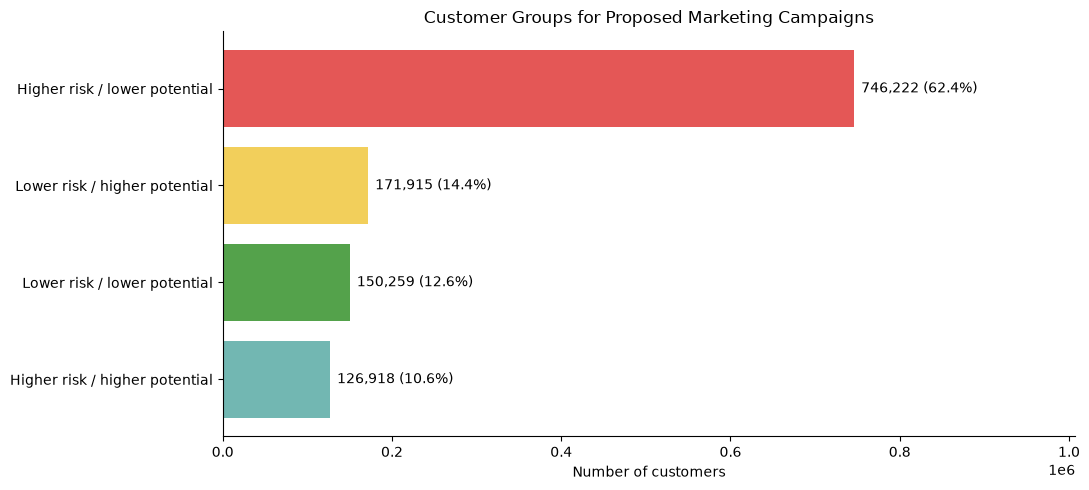

Saved customer segments: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_segments_final_2020-03-31.parquet
Saved summary, rules, and graph: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\final


In [44]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Business segmentation rules.
risk_threshold = 0.5
spending_potential_threshold = float(
    final_customer_scores["predicted_spend_if_purchase"].quantile(0.75)
)

customer_segments = final_customer_scores.copy()

higher_risk = (
    customer_segments["predicted_no_purchase_probability"]
    >= risk_threshold
)

higher_potential = (
    customer_segments["predicted_spend_if_purchase"]
    >= spending_potential_threshold
)

customer_segments["segment"] = np.select(
    [
        higher_risk & higher_potential,
        higher_risk & ~higher_potential,
        ~higher_risk & higher_potential,
    ],
    [
        "Higher risk / higher potential",
        "Higher risk / lower potential",
        "Lower risk / higher potential",
    ],
    default="Lower risk / lower potential",
)

proposed_actions = {
    "Higher risk / higher potential": "Test targeted retention offers",
    "Higher risk / lower potential": "Test low-cost re-engagement",
    "Lower risk / higher potential": "Test loyalty and cross-sell campaigns",
    "Lower risk / lower potential": "Standard communication",
}

customer_segments["proposed_action"] = (
    customer_segments["segment"].map(proposed_actions)
)

segment_summary = (
    customer_segments.groupby("segment", as_index=False)
    .agg(
        customers=("customer_id", "size"),
        average_no_purchase_risk=(
            "predicted_no_purchase_probability", "mean"
        ),
        average_estimated_spending=("estimated_future_spending", "mean"),
        total_estimated_spending=("estimated_future_spending", "sum"),
    )
)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"] / len(customer_segments) * 100
)
segment_summary["average_no_purchase_risk_pct"] = (
    segment_summary.pop("average_no_purchase_risk") * 100
)
segment_summary["proposed_action"] = (
    segment_summary["segment"].map(proposed_actions)
)

segment_summary = segment_summary.sort_values(
    "customers", ascending=False
).reset_index(drop=True)

display(segment_summary.round(4))

# Save customer-level segments separately from the aggregate report.
segment_path = (
    root / "data" / "processed"
    / "customer_segments_final_2020-03-31.parquet"
)
segment_sql_path = segment_path.as_posix().replace("'", "''")

con.register("customer_segments_export", customer_segments)

try:
    con.execute(f"""
        COPY customer_segments_export
        TO '{segment_sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
finally:
    con.unregister("customer_segments_export")

report_dir = root / "reports" / "final"
report_dir.mkdir(parents=True, exist_ok=True)

segment_summary.to_csv(
    report_dir / "customer_segment_summary.csv",
    index=False,
)

with (
    report_dir / "customer_segment_rules.json"
).open("w", encoding="utf-8") as file:
    json.dump({
        "score_as_of_date": "2020-03-31",
        "higher_risk_threshold": risk_threshold,
        "higher_potential_threshold": spending_potential_threshold,
        "potential_definition": "Predicted spending conditional on purchasing",
        "potential_threshold_rule": "75th percentile of the scored population",
        "boundary_rule": "Greater than or equal to the threshold",
        "note": "Heuristic targeting groups; campaign impact is untested.",
    }, file, indent=2)

# Simple graph: customer count in each segment.
plot_data = segment_summary.sort_values("customers")

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    plot_data["segment"],
    plot_data["customers"],
    color=["#72B7B2", "#54A24B", "#F2CF5B", "#E45756"],
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.1f}%)"
        for count, share in zip(
            plot_data["customers"],
            plot_data["customer_share_pct"],
        )
    ],
    padding=5,
)

ax.set_xlim(0, plot_data["customers"].max() * 1.35)
ax.set_xlabel("Number of customers")
ax.set_title("Customer Groups for Proposed Marketing Campaigns")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    report_dir / "customer_segments.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved customer segments:", segment_path)
print("Saved summary, rules, and graph:", report_dir)

“Higher potential” means higher predicted spending if the customer purchases. It does not mean the customer will respond to an offer or that this spending can be recovered through a campaign.

### Business interpretation of customer segments

Customers were grouped using predicted 90-day no-purchase risk and
predicted spending conditional on purchasing.

The largest segment contains 746,222 customers (62.4%) with higher
risk and lower spending potential. Low-cost re-engagement may be
appropriate for testing within this group.

A further 126,918 customers (10.6%) have higher risk and higher
spending potential, making them candidates for a focused retention
experiment. The 171,915 lower-risk, higher-potential customers
(14.4%) are candidates for loyalty and cross-selling experiments.

These groups support campaign planning. They do not establish
which customers will respond to an offer or how much additional
revenue a campaign will generate. A randomized campaign experiment
would be needed to measure that impact.

## Project results report from the saved model metadata.

In [46]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

root = Path(project_root_path)
report_dir = root / "reports" / "final"
report_dir.mkdir(parents=True, exist_ok=True)

# Read the saved, authoritative results.
with (
    root / "models" / "churn_enriched"
    / "catboost_churn_enriched_metadata.json"
).open(encoding="utf-8") as file:
    churn_info = json.load(file)

with (
    root / "models" / "spending"
    / "two_stage_spending_metadata.json"
).open(encoding="utf-8") as file:
    spending_info = json.load(file)

segments = pd.read_csv(
    report_dir / "customer_segment_summary.csv"
)

churn_metrics = churn_info["temporal_validation"]["metrics"]
spending_metrics = spending_info["temporal_validation"]["metrics"]

# Build a Markdown table without requiring an extra package.
segment_lines = [
    "| Customer segment | Customers | Share | Proposed action |",
    "|---|---:|---:|---|",
]

for row in segments.itertuples(index=False):
    segment_lines.append(
        f"| {row.segment} | {row.customers:,} | "
        f"{row.customer_share_pct:.1f}% | {row.proposed_action} |"
    )

segment_table = "\n".join(segment_lines)

report = f"""# Customer Transaction Analysis, Churn Prediction,
# and Revenue Optimization using Machine Learning and Data Visualization

## 1. Project objective

Analyze customer purchasing behavior, predict whether customers will make
no purchase during the next 90 days, estimate future customer spending,
and support customer prioritization for proposed marketing experiments.

The revenue optimization component provides decision support.
Realized revenue improvement has not been measured.

## 2. Dataset and preparation

The project uses the H&M transaction, customer, and article datasets:

- 31,788,324 purchase records.
- 1,371,980 customer records.
- 105,542 article records.
- Transaction coverage: 20 September 2018 to 22 September 2020.

DuckDB was used to process the data, and Parquet files were used for
storage. Customer-level datasets contain one row per customer.

The original modeling population contains 1,116,877 customers.
The enriched churn dataset contains 26 predictor columns.

## 3. Prediction definitions

### No-purchase prediction

- Class 0: at least one purchase in the following 90 days.
- Class 1: no purchase in the following 90 days.
- Decision threshold: {churn_info["decision_threshold"]:.2f}.

This is a definition of observed inactivity, not proof of permanent churn.

### Future spending prediction

A two-stage model combines the probability of positive spending with
predicted spending conditional on purchasing.

The regressor was trained using a log1p transformation, and its
predictions are transformed back using expm1.

All spending values are expressed in scaled dataset units.
They are not confirmed currency amounts or profit.

## 4. Model development and validation

Classification candidates included Logistic Regression, Random Forest,
HistGradientBoosting, XGBoost, and CatBoost, alongside a majority-class
baseline.

Features describe historical activity, spending, channel use, recency,
purchase gaps, product diversity, and supplied customer age.

Training snapshot:
- Feature cutoff: 31 December 2019.
- Outcome window: 1 January to 30 March 2020.

Temporal validation snapshot:
- Feature cutoff: 31 March 2020.
- Outcome window: 1 April to 29 June 2020.
- Customers: {int(churn_metrics["customers"]):,}.

The enriched feature comparison used the same training and test customers
for the baseline and enriched feature sets.

## 5. Selected churn model

Selected candidate: **CatBoost with enriched features**.

| Temporal validation metric | Result |
|---|---:|
| Accuracy | {churn_metrics["accuracy"] * 100:.2f}% |
| Precision for no purchase | {churn_metrics["precision_no_purchase"] * 100:.2f}% |
| Recall for no purchase | {churn_metrics["recall_no_purchase"] * 100:.2f}% |
| F1 for no purchase | {churn_metrics["f1_no_purchase"]:.4f} |
| ROC AUC | {churn_metrics["roc_auc"]:.4f} |
| Average precision | {churn_metrics["average_precision"]:.4f} |

The enriched boosting models performed similarly. CatBoost led narrowly
on several temporal validation metrics, but these small differences do
not establish a statistically significant advantage.

Average precision measures ranking performance and should not be
presented as classification accuracy.

## 6. Spending model results

These results were recalculated using the saved spending models and
exported predictions. Observed outcomes were joined by customer ID.

| Temporal validation metric | Result |
|---|---:|
| Actual total spending | {spending_metrics["actual_total_spending"]:,.2f} |
| Estimated total spending | {spending_metrics["estimated_total_spending"]:,.2f} |
| Aggregate estimate error | {spending_metrics["total_error_pct"]:.2f}% |
| MAE | {spending_metrics["MAE"]:.4f} |
| RMSE | {spending_metrics["RMSE"]:.4f} |
| R² | {spending_metrics["R2"]:.4f} |

The model underestimates aggregate spending. Its estimates require
further validation and calibration before use for financial planning.

## 7. Customer prioritization

Customers were segmented using predicted no-purchase risk and predicted
spending conditional on purchasing. Higher spending potential was
defined using the 75th percentile of the scored population.

{segment_table}

![Customer segment distribution](customer_segments.png)

These proposed actions are hypotheses for campaign experiments.
The model does not predict the causal effect of contacting a customer.

## 8. Limitations

- Temporal validation was repeatedly inspected during model selection;
  it is not an untouched final test.
- Customer age comes from supplied snapshot metadata. Its historical
  availability at the prediction cutoffs is unverified.
- Missing age was filled using the full customer snapshot median,
  rather than a median fitted only on training customers.
- Some engineered features are redundant with existing activity measures.
- Inverse-transforming log-scale predictions does not automatically
  recover conditional mean spending.
- The final spending model underestimates aggregate spending by
  {abs(spending_metrics["total_error_pct"]):.2f}%.
- The earlier spending total could not be fully reconciled with the
  saved model state; this report uses the recomputed saved-model results.
- No campaign experiment, incremental revenue, or profit improvement
  has been observed.

## 9. Reproducibility and deliverables

Saved artifacts include:

- CatBoost churn model and metadata.
- Two-stage spending models and metadata.
- Historical and temporal enriched feature datasets.
- Customer training/test split manifest.
- Final customer scores and segment assignments.
- Temporal model comparison, segment summary, and visualization.

The model save/load checks confirmed that reloaded models reproduced
their predictions on the verification samples.

## 10. Recommended future work

- Evaluate the frozen pipeline on a later, untouched period.
- Use historically dated customer attributes where available.
- Fit preprocessing statistics only on training data.
- Investigate spending-model calibration using separate development data.
- Run a randomized campaign experiment to measure incremental revenue
  and campaign cost.
"""

# Use one title heading.
report = report.replace(
    "# Customer Transaction Analysis, Churn Prediction,\n"
    "# and Revenue Optimization using Machine Learning and Data Visualization",
    "# Customer Transaction Analysis, Churn Prediction, and Revenue "
    "Optimization using Machine Learning and Data Visualization",
)

report_path = report_dir / "project_results_report.md"
report_path.write_text(report, encoding="utf-8")

print("Saved report:", report_path)

# Preview the text in the notebook.
display(Markdown(report))

Saved report: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\final\project_results_report.md


# Customer Transaction Analysis, Churn Prediction, and Revenue Optimization using Machine Learning and Data Visualization

## 1. Project objective

Analyze customer purchasing behavior, predict whether customers will make
no purchase during the next 90 days, estimate future customer spending,
and support customer prioritization for proposed marketing experiments.

The revenue optimization component provides decision support.
Realized revenue improvement has not been measured.

## 2. Dataset and preparation

The project uses the H&M transaction, customer, and article datasets:

- 31,788,324 purchase records.
- 1,371,980 customer records.
- 105,542 article records.
- Transaction coverage: 20 September 2018 to 22 September 2020.

DuckDB was used to process the data, and Parquet files were used for
storage. Customer-level datasets contain one row per customer.

The original modeling population contains 1,116,877 customers.
The enriched churn dataset contains 26 predictor columns.

## 3. Prediction definitions

### No-purchase prediction

- Class 0: at least one purchase in the following 90 days.
- Class 1: no purchase in the following 90 days.
- Decision threshold: 0.50.

This is a definition of observed inactivity, not proof of permanent churn.

### Future spending prediction

A two-stage model combines the probability of positive spending with
predicted spending conditional on purchasing.

The regressor was trained using a log1p transformation, and its
predictions are transformed back using expm1.

All spending values are expressed in scaled dataset units.
They are not confirmed currency amounts or profit.

## 4. Model development and validation

Classification candidates included Logistic Regression, Random Forest,
HistGradientBoosting, XGBoost, and CatBoost, alongside a majority-class
baseline.

Features describe historical activity, spending, channel use, recency,
purchase gaps, product diversity, and supplied customer age.

Training snapshot:
- Feature cutoff: 31 December 2019.
- Outcome window: 1 January to 30 March 2020.

Temporal validation snapshot:
- Feature cutoff: 31 March 2020.
- Outcome window: 1 April to 29 June 2020.
- Customers: 1,195,314.

The enriched feature comparison used the same training and test customers
for the baseline and enriched feature sets.

## 5. Selected churn model

Selected candidate: **CatBoost with enriched features**.

| Temporal validation metric | Result |
|---|---:|
| Accuracy | 76.37% |
| Precision for no purchase | 77.50% |
| Recall for no purchase | 88.71% |
| F1 for no purchase | 0.8273 |
| ROC AUC | 0.8198 |
| Average precision | 0.8763 |

The enriched boosting models performed similarly. CatBoost led narrowly
on several temporal validation metrics, but these small differences do
not establish a statistically significant advantage.

Average precision measures ranking performance and should not be
presented as classification accuracy.

## 6. Spending model results

These results were recalculated using the saved spending models and
exported predictions. Observed outcomes were joined by customer ID.

| Temporal validation metric | Result |
|---|---:|
| Actual total spending | 102,602.98 |
| Estimated total spending | 75,377.98 |
| Aggregate estimate error | -26.53% |
| MAE | 0.0786 |
| RMSE | 0.1744 |
| R² | 0.3313 |

The model underestimates aggregate spending. Its estimates require
further validation and calibration before use for financial planning.

## 7. Customer prioritization

Customers were segmented using predicted no-purchase risk and predicted
spending conditional on purchasing. Higher spending potential was
defined using the 75th percentile of the scored population.

| Customer segment | Customers | Share | Proposed action |
|---|---:|---:|---|
| Higher risk / lower potential | 746,222 | 62.4% | Test low-cost re-engagement |
| Lower risk / higher potential | 171,915 | 14.4% | Test loyalty and cross-sell campaigns |
| Lower risk / lower potential | 150,259 | 12.6% | Standard communication |
| Higher risk / higher potential | 126,918 | 10.6% | Test targeted retention offers |

![Customer segment distribution](customer_segments.png)

These proposed actions are hypotheses for campaign experiments.
The model does not predict the causal effect of contacting a customer.

## 8. Limitations

- Temporal validation was repeatedly inspected during model selection;
  it is not an untouched final test.
- Customer age comes from supplied snapshot metadata. Its historical
  availability at the prediction cutoffs is unverified.
- Missing age was filled using the full customer snapshot median,
  rather than a median fitted only on training customers.
- Some engineered features are redundant with existing activity measures.
- Inverse-transforming log-scale predictions does not automatically
  recover conditional mean spending.
- The final spending model underestimates aggregate spending by
  26.53%.
- The earlier spending total could not be fully reconciled with the
  saved model state; this report uses the recomputed saved-model results.
- No campaign experiment, incremental revenue, or profit improvement
  has been observed.

## 9. Reproducibility and deliverables

Saved artifacts include:

- CatBoost churn model and metadata.
- Two-stage spending models and metadata.
- Historical and temporal enriched feature datasets.
- Customer training/test split manifest.
- Final customer scores and segment assignments.
- Temporal model comparison, segment summary, and visualization.

The model save/load checks confirmed that reloaded models reproduced
their predictions on the verification samples.

## 10. Recommended future work

- Evaluate the frozen pipeline on a later, untouched period.
- Use historically dated customer attributes where available.
- Fit preprocessing statistics only on training data.
- Investigate spending-model calibration using separate development data.
- Run a randomized campaign experiment to measure incremental revenue
  and campaign cost.
